# PINN vs Classical Numerical Solver for Singular Three-Point BVPs

## Final clean, controlled notebook (PyTorch, runs locally on a GPU or CPU)

This notebook has **one purpose**: reproduce the paper's four main PINN configurations on Examples 3.1–3.3 and then compare the best PINN result with a classical **finite-difference numerical solver** on exactly the same benchmark problems.

### What is included
1. Standard PINN
2. PINN + L1 regularization
3. PINN + L2 regularization
4. A-PINN
5. Exact-solution evaluation using RMSE, MAE, MAPE, R², Pearson R, rSD, NSE and RE
6. Finite-difference solver with the nonlocal three-point boundary condition
7. PINN-vs-FD accuracy and wall-clock comparison
8. FD grid-convergence study (N = 50, 100, 200, 400)

### Experimental settings (10 seeds × 10,000 epochs)
- 10,000 epochs per run (see `FULL_EPOCHS` in the Setup cell)
- 10 random seeds (0–9) for every PINN configuration
- 500 collocation points
- 20 neurons × 3 hidden layers
- tanh activation
- Adam, learning rate 1e-3
- L1/L2 coefficient 1e-3
- an auxiliary depth/activation sweep (1 seed × 3,000 epochs) is run only to redraw the paper-style figures
- no RAR/SoftAdapt or other extra methods

### Important scientific note
The paper's benchmark equations contain singular coefficients at the endpoints. The PINN training therefore uses a mathematically equivalent **stabilized residual** obtained by multiplying the residual by the singular coefficient factor. Collocation points are sampled away from the exact singular endpoints, while the boundary conditions are still enforced at t=0, t=1 and the interior point.

The finite-difference method also does **not** evaluate the singular ODE at the endpoints; it imposes the boundary conditions there and applies the differential equation only at interior grid points.

### Fairness rule
The four PINN variants use the **same seed, architecture, optimizer, learning rate, epoch budget and collocation budget**. A deterministic finite-difference solver has no epochs or random seed, so it is compared using its fixed grid and a convergence study rather than artificially assigning it a seed or epochs.

### How to use
Run the notebook **top-to-bottom** in a local Jupyter / VS Code kernel that has PyTorch installed (the CUDA build for NVIDIA GPUs). Run the device-check cell after the training function first, and set `QUICK_TEST = True` for a 20-epoch smoke test before the full run.

## 1. Setup and experimental design

This version is the **multi-seed, 10,000-epoch experimental run**. It keeps the same three singular TPS-BVP benchmarks and the same four PINN variants, but repeats every PINN configuration over 10 random seeds.

### Main PINN experiment
- 3 benchmark problems
- 4 PINN variants
- 10 random seeds: 0–9
- 10,000 epochs per run
- 500 collocation points
- 3 hidden layers × 20 tanh neurons
- Adam, learning rate 1e-3

Total PINN runs: **3 × 4 × 10 = 120**.

The finite-difference baseline remains deterministic and is evaluated separately on N=400, followed by a grid-convergence study at N=50, 100, 200, 400.

In [23]:
# ============================================================
# 1. SETUP — 10-SEED / 10,000-EPOCH COLAB EXPERIMENT
# ============================================================

import math
import time
import os
import gc
import pickle
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import torch
import torch.nn as nn
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import spsolve

# -----------------------------
# Reproducibility / experiment budget
# -----------------------------
FULL_SEEDS = list(range(10))     # 10 independent initialization seeds
FULL_EPOCHS = 10_000             # aligned with the paper's larger budget

# Set QUICK_TEST = True only for a short code check. For the real experiment
# leave it False.
QUICK_TEST = False
SEEDS = [0] if QUICK_TEST else FULL_SEEDS
EPOCHS = 20 if QUICK_TEST else FULL_EPOCHS
N_COLLOC = 500
LR = 1e-3

HIDDEN = 20
DEPTH = 3
ACTIVATION = "tanh"

LAMBDA_L1 = 1e-3
LAMBDA_L2 = 1e-3

# A-PINN: refresh the adaptive loss weights every this many epochs.
# (The original TensorFlow Example 3.1 code refreshed them every epoch, i.e. 1.)
APINN_UPDATE_EVERY = 500

# The raw paper residual contains 1/t or 1/[t(1-t)].
# Multiplying by the singular coefficient factor gives an
# equivalent residual for 0<t<1 and improves conditioning.
USE_STABILIZED_RESIDUAL = True

# Finite-difference grid for the main numerical comparison.
FD_N = 400
FD_GRID_SIZES = [50, 100, 200, 400]

MODES = ["standard", "l1", "l2", "apinn"]
MODE_LABELS = {
    "standard": "PINN",
    "l1": "PINN + L1",
    "l2": "PINN + L2",
    "apinn": "A-PINN"
}

# -----------------------------
# Device: use the laptop GPU whenever PyTorch can see one
# -----------------------------
DEVICE_OVERRIDE = None        # force a device with "cpu", "cuda" or "mps"; None = automatic


def pick_device():
    if torch.cuda.is_available():
        return torch.device("cuda")                                    # NVIDIA GPU
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")                                     # Apple-silicon GPU
    return torch.device("cpu")


DEVICE = torch.device(DEVICE_OVERRIDE) if DEVICE_OVERRIDE else pick_device()


def sync(dev=None):
    """Block until queued GPU work has finished, so wall-clock timings are honest."""
    dev = dev or DEVICE
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()


# float32 matches the original PyTorch notebooks. Use torch.float64 to match the paper's
# original TensorFlow code (CUDA and CPU only: Apple's MPS backend has no float64).
DTYPE = torch.float32
torch.set_default_dtype(DTYPE)

# CSV files and checkpoints are written to this local folder.
OUT_DIR = "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

# -----------------------------
# Checkpointing
# -----------------------------
# If the run is interrupted (laptop sleep, crash) after some completed runs, rerunning this notebook
# will reuse completed runs from this file and continue from the next one.
# Set RESUME = False if you deliberately want a fresh experiment.
RESUME = True
CHECKPOINT_FILE = os.path.join(OUT_DIR, "pinn_multiseed_10k_checkpoint.pkl")
os.makedirs(os.path.dirname(CHECKPOINT_FILE), exist_ok=True)

CONFIG_TEXT = str({
    "seeds": SEEDS,
    "epochs": EPOCHS,
    "n_colloc": N_COLLOC,
    "lr": LR,
    "hidden": HIDDEN,
    "depth": DEPTH,
    "activation": ACTIVATION,
    "l1": LAMBDA_L1,
    "l2": LAMBDA_L2,
    "fd_n": FD_N,
    "modes": MODES,
    "stabilized": USE_STABILIZED_RESIDUAL,
    "dtype": str(DTYPE),
    "apinn_every": APINN_UPDATE_EVERY
})
CONFIG_ID = hashlib.md5(CONFIG_TEXT.encode()).hexdigest()[:10]

print("PyTorch:", torch.__version__)
print("Device:", DEVICE, f"({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else "")
if DEVICE.type == "cpu" and DEVICE_OVERRIDE is None:
    print("NOTE: PyTorch is running on the CPU. If your laptop has an NVIDIA GPU, install the CUDA build of "
          "PyTorch (https://pytorch.org/get-started/locally/) and restart the kernel.")
print(f"Seeds={SEEDS}")
print(f"Epochs={EPOCHS} | Collocation={N_COLLOC}")
print(f"Network={HIDDEN} neurons x {DEPTH} hidden layers | activation={ACTIVATION} | FD N={FD_N}")
print(f"Total PINN runs = {len(SEEDS)} seeds x {len(MODES)} methods x 3 examples = {len(SEEDS)*len(MODES)*3}")
print("Checkpoint:", CHECKPOINT_FILE)
print("Config ID:", CONFIG_ID)

PyTorch: 2.14.1+cpu
Device: cpu 
NOTE: PyTorch is running on the CPU. If your laptop has an NVIDIA GPU, install the CUDA build of PyTorch (https://pytorch.org/get-started/locally/) and restart the kernel.
Seeds=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Epochs=10000 | Collocation=500
Network=20 neurons x 3 hidden layers | activation=tanh | FD N=400
Total PINN runs = 10 seeds x 4 methods x 3 examples = 120
Checkpoint: outputs\pinn_multiseed_10k_checkpoint.pkl
Config ID: e2a6527ac6


### Running locally on your GPU

**One-time install.** Pick your platform / CUDA version at https://pytorch.org/get-started/locally/ for PyTorch, then:

```
pip install numpy scipy pandas matplotlib jupyter ipython
```

Check that PyTorch can see the GPU: `python -c "import torch; print(torch.cuda.is_available())"`. If this prints `False` on a machine with an NVIDIA GPU, a CPU-only PyTorch wheel is installed — reinstall using the selector above.

**Runtime.** The full run is **120 PINN trainings, each with 10,000 epochs**. Results are checkpointed to `outputs/` after every run, and the notebook resumes automatically if it is interrupted (sleep, closed lid, crash), so keep the laptop plugged in and awake.

**Smoke test first.** Set `QUICK_TEST = True` (1 seed, 20 epochs) and run the whole notebook once to confirm everything works, then set it back to `False`.

**GPU vs CPU.** The networks are very small, so run the *device check* cell below the training function to see which device is faster on your machine.


## 2. Problem definitions

In [2]:

# General three-point boundary conditions:
# y(0) = alpha
# y(1) = epsilon*y(theta) + beta

class Problem:
    def __init__(self, name, alpha, epsilon, theta, beta,
                 exact_fn, paper_residual, stable_residual):
        self.name = name
        self.alpha = alpha
        self.epsilon = epsilon
        self.theta = theta
        self.beta = beta
        self.exact_fn = exact_fn
        self.paper_residual = paper_residual
        self.stable_residual = stable_residual


# -----------------------------
# Example 3.1
# y = sin(pi t)
# -----------------------------
def ex1_paper(t, y, yt, ytt):
    return (
        ytt
        + (2.0 / t) * yt
        + math.pi**2 * torch.sin(math.pi * t)
        - (2.0 * math.pi * torch.cos(math.pi * t)) / t
    )

def ex1_stable(t, y, yt, ytt):
    # t * original residual
    return (
        t * ytt
        + 2.0 * yt
        + math.pi**2 * t * torch.sin(math.pi * t)
        - 2.0 * math.pi * torch.cos(math.pi * t)
    )


# -----------------------------
# Example 3.2
# y = sinh(t)
# -----------------------------
def ex2_paper(t, y, yt, ytt):
    return (
        ytt
        + yt / t
        + y / (t * (1.0 - t))
        - torch.sinh(t) / (t * (1.0 - t))
        - torch.cosh(t) / t
        - torch.sinh(t)
    )

def ex2_stable(t, y, yt, ytt):
    # t(1-t) * original residual
    return (
        t * (1.0 - t) * ytt
        + (1.0 - t) * yt
        + y
        - torch.sinh(t)
        - (1.0 - t) * torch.cosh(t)
        - t * (1.0 - t) * torch.sinh(t)
    )


# -----------------------------
# Example 3.3
# y = sinh(t), nonlinear
# -----------------------------
def ex3_paper(t, y, yt, ytt):
    return (
        ytt
        + 6.0 * yt / (t * (1.0 - t))
        + (y**2 + 2.0*y - 6.0*torch.cosh(t)) / (t * (1.0 - t))
        - (torch.sinh(t) / (t * (1.0 - t)))
          * (torch.sinh(t) - t**2 + t + 2.0)
    )

def ex3_stable(t, y, yt, ytt):
    # t(1-t) * original residual
    return (
        t * (1.0 - t) * ytt
        + 6.0 * yt
        + y**2
        + 2.0*y
        - 6.0*torch.cosh(t)
        - torch.sinh(t) * (torch.sinh(t) - t**2 + t + 2.0)
    )


PROBLEMS = {
    "3.1": Problem(
        "Example 3.1: y(t) = sin(pi t)",
        alpha=0.0, epsilon=0.5, theta=0.5, beta=-0.5,
        exact_fn=lambda t: np.sin(np.pi*t),
        paper_residual=ex1_paper,
        stable_residual=ex1_stable
    ),
    "3.2": Problem(
        "Example 3.2: y(t) = sinh(t)",
        alpha=0.0, epsilon=-0.5, theta=0.8,
        beta=math.sinh(1.0) + 0.5*math.sinh(0.8),
        exact_fn=lambda t: np.sinh(t),
        paper_residual=ex2_paper,
        stable_residual=ex2_stable
    ),
    "3.3": Problem(
        "Example 3.3: y(t) = sinh(t), nonlinear",
        alpha=0.0, epsilon=-0.5, theta=0.8,
        beta=math.sinh(1.0) + 0.5*math.sinh(0.8),
        exact_fn=lambda t: np.sinh(t),
        paper_residual=ex3_paper,
        stable_residual=ex3_stable
    )
}

for k, p in PROBLEMS.items():
    print(k, p.name)


3.1 Example 3.1: y(t) = sin(pi t)
3.2 Example 3.2: y(t) = sinh(t)
3.3 Example 3.3: y(t) = sinh(t), nonlinear


## 3. PINN architecture and derivatives

In [3]:
# ============================================================
# 3. PINN ARCHITECTURE — WIDTH, DEPTH AND ACTIVATION SUPPORT
# ============================================================

def get_activation(name):
    name = name.lower()
    if name == "tanh":
        return nn.Tanh()
    if name == "selu":
        return nn.SELU()
    if name == "relu":
        return nn.ReLU()
    if name == "sigmoid":
        return nn.Sigmoid()
    raise ValueError(f"Unsupported activation: {name}")


class MLP(nn.Module):
    def __init__(self, width=HIDDEN, depth=DEPTH, activation=ACTIVATION):
        super().__init__()
        layers = [nn.Linear(1, width), get_activation(activation)]
        for _ in range(depth - 1):
            layers += [nn.Linear(width, width), get_activation(activation)]
        layers += [nn.Linear(width, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, t):
        return self.net(t)


def derivatives(net, t):
    t = t.clone().detach().requires_grad_(True)
    y = net(t)

    yt = torch.autograd.grad(
        y, t, torch.ones_like(y), create_graph=True
    )[0]

    ytt = torch.autograd.grad(
        yt, t, torch.ones_like(yt), create_graph=True
    )[0]

    return y, yt, ytt


## 4. PINN losses

In [4]:

def compute_losses(net, problem, t_col):
    y, yt, ytt = derivatives(net, t_col)

    residual_fn = (
        problem.stable_residual
        if USE_STABILIZED_RESIDUAL
        else problem.paper_residual
    )

    residual = residual_fn(t_col, y, yt, ytt)
    Lf = torch.mean(residual**2)

    t0 = torch.tensor([[0.0]], dtype=DTYPE, device=DEVICE)
    t1 = torch.tensor([[1.0]], dtype=DTYPE, device=DEVICE)
    ttheta = torch.tensor(
        [[problem.theta]], dtype=DTYPE, device=DEVICE
    )

    y0 = net(t0)
    y1 = net(t1)
    ytheta = net(ttheta)

    bc_res = y1 - (problem.epsilon * ytheta + problem.beta)
    Lbc = torch.mean((y0 - problem.alpha)**2 + bc_res**2)

    return Lf, Lbc


def weight_penalty(net, order):
    total = torch.tensor(0.0, device=DEVICE)
    for p in net.parameters():
        if order == 1:
            total = total + torch.sum(torch.abs(p))
        else:
            total = total + torch.sum(p**2)
    return total


def grad_norm(loss, net, retain_graph=False):
    grads = torch.autograd.grad(
        loss,
        net.parameters(),
        retain_graph=retain_graph,
        create_graph=False,
        allow_unused=True
    )
    total = torch.tensor(0.0, device=DEVICE)
    for g in grads:
        if g is not None:
            total = total + torch.sum(g**2)
    return torch.sqrt(total + 1e-12)


## 5. Training

In [5]:
def train(problem, mode="standard", epochs=EPOCHS,
          n_colloc=N_COLLOC, lr=LR, seed=0, width=HIDDEN, depth=DEPTH, activation=ACTIVATION):
    """Train one PINN configuration with a fixed seed and budget."""
    torch.manual_seed(seed)
    np.random.seed(seed)

    net = MLP(width=width, depth=depth, activation=activation).to(DEVICE)
    optimizer = torch.optim.Adam(net.parameters(), lr=lr)

    # Do not evaluate singular coefficients exactly at t=0 or t=1.
    t_col = torch.linspace(1e-3, 1.0 - 1e-3, n_colloc, device=DEVICE).view(-1, 1)

    w_f, w_bc = 1.0, 1.0

    # Keep the loss curve on the device and copy it to the host once at the end:
    # float(loss) every epoch would force a GPU->CPU sync and stall the GPU.
    hist = torch.zeros(epochs, device=DEVICE)
    sync()
    start = time.perf_counter()

    for ep in range(epochs):
        optimizer.zero_grad(set_to_none=True)

        Lf, Lbc = compute_losses(net, problem, t_col)

        if mode == "standard":
            loss = Lf + Lbc

        elif mode == "l1":
            loss = Lf + Lbc + LAMBDA_L1 * weight_penalty(net, order=1)

        elif mode == "l2":
            loss = Lf + Lbc + LAMBDA_L2 * weight_penalty(net, order=2)

        elif mode == "apinn":
            # Update adaptive weights every APINN_UPDATE_EVERY epochs. This keeps the
            # adaptive-loss idea while avoiding unnecessary overhead during
            # the 10,000-epoch multi-seed experiment.
            if ep % APINN_UPDATE_EVERY == 0:
                tb = t_col[:min(100, n_colloc)]
                Lf_b, Lbc_b = compute_losses(net, problem, tb)
                gf = grad_norm(Lf_b, net, retain_graph=True).item()
                gb = grad_norm(Lbc_b, net, retain_graph=False).item()

                af = 1.0 / (gf + 1e-8)
                ab = 1.0 / (gb + 1e-8)
                s = af + ab
                w_f = 2.0 * af / s
                w_bc = 2.0 * ab / s

            loss = w_f * Lf + w_bc * Lbc

        else:
            raise ValueError(f"Unknown mode: {mode}")

        loss.backward()
        optimizer.step()
        hist[ep] = loss.detach()

    sync()
    elapsed = time.perf_counter() - start
    history = hist.cpu().tolist()
    return net, history, elapsed

### Optional: 10-second device check (CPU vs GPU)

These networks are tiny (1 → 20 → 20 → 20 → 1 on a few hundred points), so a GPU is **not guaranteed** to beat the CPU: per-step launch overhead can dominate. Run this cell once. It times a few hundred epochs on each device and tells you which one is faster on *your* laptop. If the CPU wins, set `DEVICE_OVERRIDE = "cpu"` in the setup cell.


In [6]:
def benchmark_devices(n_epochs=300):
    """Time a few hundred standard-PINN epochs on every available device."""
    global DEVICE
    original = DEVICE
    candidates = [torch.device("cpu")] + ([original] if original.type != "cpu" else [])
    timings = {}
    try:
        for dev in candidates:
            DEVICE = dev
            train(PROBLEMS["3.1"], mode="standard", epochs=20)                   # warm-up (CUDA start-up, kernel setup)
            _, _, secs = train(PROBLEMS["3.1"], mode="standard", epochs=n_epochs)
            timings[str(dev)] = 1000.0 * secs / n_epochs
            print(f"{str(dev):>5s}: {timings[str(dev)]:6.2f} ms/epoch  ->  about "
                  f"{timings[str(dev)] * EPOCHS / 1000:,.0f} s for one {EPOCHS:,}-epoch run")
    finally:
        DEVICE = original
    if len(timings) == 2:
        faster = min(timings, key=timings.get)
        hint = "" if faster == str(original) else f'  Set DEVICE_OVERRIDE = "{faster}" in the setup cell to use it.'
        print(f"\nFaster on this machine: {faster}.{hint}")
    return timings


benchmark_devices()


  cpu:   3.04 ms/epoch  ->  about 30 s for one 10,000-epoch run


{'cpu': 3.039237666665334}

## 6. Statistical evaluation

In [7]:
def stats_table(y_true, y_pred):
    err = y_true - y_pred
    mse = float(np.mean(err**2))
    rmse = float(np.sqrt(mse))
    mae = float(np.mean(np.abs(err)))

    # MAPE is undefined at reference values equal to zero.
    nz = np.abs(y_true) > 1e-12
    mape = float(100.0 * np.mean(np.abs(err[nz] / y_true[nz])))

    ss_res = float(np.sum(err**2))
    ss_tot = float(np.sum((y_true - np.mean(y_true))**2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    r = float(np.corrcoef(y_true, y_pred)[0, 1])
    re = float(np.linalg.norm(err) / np.linalg.norm(y_true))
    rsd = float(100.0 * np.std(err) / np.mean(y_true))

    return {
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape,
        "R2": r2,
        "R": r,
        "rSD (%)": rsd,
        "NSE": r2,
        "RE": re
    }


def evaluate(net, problem, n_test=1000):
    t = np.linspace(0.0, 1.0, n_test)
    tt = torch.tensor(t, dtype=DTYPE, device=DEVICE).view(-1, 1)

    net.eval()
    with torch.no_grad():
        y_pred = net(tt).cpu().numpy().ravel()

    y_true = problem.exact_fn(t)
    return t, y_true, y_pred, stats_table(y_true, y_pred)

## 7. Paper reference tables (reported values)

The next cells preserve the paper-reported tables as **reference only**. They are not mixed with our new 10-seed results. The paper reports Tables 1–5 and uses the metrics MSE, RMSE, MAE, MAPE, R², Pearson R, rSD, NSE and RE.

In [8]:
# ============================================================
# PAPER TABLE 1 — METRIC DEFINITIONS (REFERENCE)
# ============================================================
paper_table1 = pd.DataFrame([
    ["MSE", "Mean squared error", ">= 0; lower is better"],
    ["RMSE", "Square root of MSE", "Same units as y; >= 0"],
    ["MAE", "Mean absolute error", ">= 0; robust to outliers vs MSE"],
    ["MAPE", "100/n * sum(|(y-yhat)/y|)", "% error; undefined when y=0"],
    ["R²", "1 - SS_res / SS_tot", "(-inf, 1]; 1 is perfect"],
    ["R (Pearson)", "Pearson correlation coefficient", "[-1, 1]; linear association"],
    ["RE", "||y-yhat||₂ / ||y||₂", ">= 0; scale-free"],
    ["rSD", "Std(y-yhat) / mean(y) * 100", "Depends on mean(y) != 0"],
    ["NSE", "1 - SS_res / SS_tot", "(-inf, 1]; 1 is perfect"],
], columns=["Metric", "Definition", "Range / notes"])
display(paper_table1)


,Metric,Definition,Range / notes
0,MSE,Mean squared error,>= 0; lower is better
1,RMSE,Square root of MSE,Same units as y; >= 0
2,MAE,Mean absolute error,>= 0; robust to outliers vs MSE
3,MAPE,100/n * sum(|(y-yhat)/y|),% error; undefined when y=0
4,R²,1 - SS_res / SS_tot,"(-inf, 1]; 1 is perfect"
5,R (Pearson),Pearson correlation coefficient,"[-1, 1]; linear association"
6,RE,||y-yhat||₂ / ||y||₂,>= 0; scale-free
7,rSD,Std(y-yhat) / mean(y) * 100,Depends on mean(y) != 0
8,NSE,1 - SS_res / SS_tot,"(-inf, 1]; 1 is perfect"


In [9]:
# ============================================================
# PAPER TABLES 2–4 — REPORTED STATISTICS (REFERENCE ONLY)
# ============================================================
paper_t2 = pd.DataFrame({
    "Metric":["RMSE","MAE","MAPE","R2","R","rSD","NSE","RE"],
    "PINN":[0.000326,0.002449,0.39,0.9999,1.0000,0.9999,0.9999,0.0039],
    "PINN + L1":[0.004668,0.004715,0.41,0.9998,1.0000,1.0002,0.9998,0.0041],
    "PINN + L2":[0.000157,0.001260,0.92,1.0000,1.0000,0.9999,1.0000,0.0092],
    "A-PINN":[0.000632,0.005010,0.17,0.9997,0.9998,0.0062,0.9996,0.0172],
})
paper_t3 = pd.DataFrame({
    "Metric":["RMSE","MAE","MAPE","R2","R","rSD","NSE","RE"],
    "PINN":[0.004057,0.004906,1.08,0.9997,1.0000,0.9843,0.9997,0.0108],
    "PINN + L1":[0.018528,0.020891,5.32,0.9959,1.0000,1.0063,0.9959,0.0532],
    "PINN + L2":[0.005990,0.011005,2.32,0.9988,1.0000,0.9919,0.9988,0.0232],
    "A-PINN":[0.006374,0.04705,1.61,0.9981,0.9990,0.9935,0.9991,0.1616],
})
paper_t4 = pd.DataFrame({
    "Metric":["RMSE","MAE","MAPE","R2","R","rSD","NSE","RE"],
    "PINN":[0.001070,0.007509,1.02,0.9995,1.0000,1.0014,0.9995,0.0102],
    "PINN + L1":[0.000957,0.001319,0.23,1.0000,1.0000,1.0033,1.0000,0.0023],
    "PINN + L2":[0.000893,0.001164,1.16,1.0000,1.0000,1.0027,1.0000,0.0116],
    "A-PINN":[0.007987,0.007101,4.81,0.99941,0.9999,0.00946,0.99941,0.0481],
})
print("Paper Table 2 — Example 3.1")
display(paper_t2)
print("Paper Table 3 — Example 3.2")
display(paper_t3)
print("Paper Table 4 — Example 3.3")
display(paper_t4)


Paper Table 2 — Example 3.1


,Metric,PINN,PINN + L1,PINN + L2,A-PINN
0,RMSE,0.000326,0.004668,0.000157,0.000632
1,MAE,0.002449,0.004715,0.001260,0.005010
2,MAPE,0.390000,0.410000,0.920000,0.170000
3,R2,0.999900,0.999800,1.000000,0.999700
4,R,1.000000,1.000000,1.000000,0.999800
5,rSD,0.999900,1.000200,0.999900,0.006200
6,NSE,0.999900,0.999800,1.000000,0.999600
7,RE,0.003900,0.004100,0.009200,0.017200


Paper Table 3 — Example 3.2


,Metric,PINN,PINN + L1,PINN + L2,A-PINN
0,RMSE,0.004057,0.018528,0.005990,0.006374
1,MAE,0.004906,0.020891,0.011005,0.047050
2,MAPE,1.080000,5.320000,2.320000,1.610000
3,R2,0.999700,0.995900,0.998800,0.998100
4,R,1.000000,1.000000,1.000000,0.999000
5,rSD,0.984300,1.006300,0.991900,0.993500
6,NSE,0.999700,0.995900,0.998800,0.999100
7,RE,0.010800,0.053200,0.023200,0.161600


Paper Table 4 — Example 3.3


,Metric,PINN,PINN + L1,PINN + L2,A-PINN
0,RMSE,0.001070,0.000957,0.000893,0.007987
1,MAE,0.007509,0.001319,0.001164,0.007101
2,MAPE,1.020000,0.230000,1.160000,4.810000
3,R2,0.999500,1.000000,1.000000,0.999410
4,R,1.000000,1.000000,1.000000,0.999900
5,rSD,1.001400,1.003300,1.002700,0.009460
6,NSE,0.999500,1.000000,1.000000,0.999410
7,RE,0.010200,0.002300,0.011600,0.048100


In [10]:
# ============================================================
# PAPER TABLE 5 — FULL REPORTED MSE GRID (REFERENCE ONLY)
# ============================================================
# Values below are transcribed from the paper's Table 5.
# They are kept separate from our new experimental results.
rows=[]
def add5(epoch,act,width,vals):
    methods=["PINN","PINN + L1","PINN + L2","A-PINN"]
    for method,trip in zip(methods,vals):
        rows.append([epoch,act,width,method,*trip])
add5(5000,"tanh","[20,20,20]",[(.218824,.002053,.009721),(.192392,.001895,.008119),(.170529,.001680,.007197),(.142108,.001400,.005997)])
add5(5000,"tanh","[30,30,30]",[(.322930,.007213,.002319),(.281962,.006613,.001924),(.252339,.005918,.001721),(.212549,.004985,.001450)])
add5(5000,"tanh","[50,50,50]",[(.386446,.005057,.006640),(.334620,.004598,.005462),(.284666,.003911,.004647),(.242485,.003332,.003958)])
add5(5000,"selu","[20,20,20]",[(.080107,.018193,.004628),(.074133,.017678,.004069),(.068024,.016221,.003733),(.056475,.013467,.003100)])
add5(5000,"selu","[30,30,30]",[(.070599,.017355,.012716),(.064873,.016745,.011100),(.056571,.014602,.009680),(.050427,.013016,.008629)])
add5(5000,"selu","[50,50,50]",[(.071193,.008649,.001811),(.065488,.008153,.001654),(.057715,.007288,.001381),(.048485,.006185,.001172)])
add5(5000,"relu","[20,20,20]",[(.779014,.023888,.717854),(.760353,.024815,.694106),(.709941,.023022,.646807),(.625129,.020341,.562414)])
add5(5000,"relu","[30,30,30]",[(.510609,.017485,.346871),(.495091,.018188,.333580),(.447145,.016498,.302380),(.410205,.015025,.277303)])
add5(5000,"relu","[50,50,50]",[(.599544,.011970,.088490),(.550392,.011226,.083980),(.513275,.010511,.078431),(.466142,.009573,.071030)])
add5(5000,"sigmoid","[20,20,20]",[(1.467156,.255956,.602457),(1.201271,.227963,.467085),(1.040022,.199513,.407344),(.884788,.173436,.351812)])
add5(5000,"sigmoid","[30,30,30]",[(.436951,.223094,.397432),(.358356,.198761,.308439),(.301536,.173892,.267858),(.256828,.150593,.229718)])
add5(5000,"sigmoid","[50,50,50]",[(1.525069,.231441,.249954),(1.227773,.205649,.190042),(1.015706,.179716,.159690),(.894901,.156665,.137116)])
add5(10000,"tanh","[20,20,20]",[(.210464,.003853,.005267),(.191493,.003686,.004294),(.165361,.003248,.003774),(.136135,.002598,.003028)])
add5(10000,"tanh","[30,30,30]",[(.161954,.002263,.008855),(.139526,.002152,.007160),(.121140,.001884,.006290),(.101385,.001507,.005219)])
add5(10000,"tanh","[50,50,50]",[(.132757,.001140,.001970),(.109167,.000968,.001513),(.094378,.000867,.001355),(.075904,.000715,.001118)])
add5(10000,"selu","[20,20,20]",[(.054094,.011599,.007563),(.051361,.011764,.006770),(.046359,.010512,.006084),(.037891,.008635,.004998)])
add5(10000,"selu","[30,30,30]",[(.038798,.008781,.002166),(.035798,.008842,.001922),(.031001,.007831,.001681),(.025007,.005943,.001326)])
add5(10000,"selu","[50,50,50]",[(.042377,.003194,.002118),(.037336,.003041,.001792),(.032963,.002712,.001566),(.027225,.002154,.001254)])
add5(10000,"relu","[20,20,20]",[(.752730,.010215,1.456074),(.738560,.010529,1.369680),(.681761,.009429,1.258265),(.582068,.008201,1.090835)])
add5(10000,"relu","[30,30,30]",[(.286082,.009903,.696064),(.264598,.009626,.621120),(.246739,.008722,.565241),(.203842,.007410,.479585)])
add5(10000,"relu","[50,50,50]",[(.042232,.005027,.350766),(.038125,.004929,.313173),(.034889,.004412,.284812),(.028997,.003723,.243461)])
add5(10000,"sigmoid","[20,20,20]",[(.388610,.138549,.296871),(.314182,.127036,.220978),(.276559,.110919,.193701),(.230289,.096624,.164986)])
add5(10000,"sigmoid","[30,30,30]",[(.211389,.119513,.210334),(.165417,.107077,.155168),(.146845,.093102,.137355),(.122400,.080875,.116802)])
add5(10000,"sigmoid","[50,50,50]",[(1.088798,.011036,.134353),(.859713,.010268,.098170),(.737813,.008889,.082622),(.606310,.006453,.071075)])
paper_table5 = pd.DataFrame(rows, columns=["Epochs","Activation","Hidden Neurons","Method","Exp. 1 MSE","Exp. 2 MSE","Exp. 3 MSE"])

add5(15000,"tanh","[20,20,20]",[(.198540,.003120,.004612),(.177882,.002986,.003781),(.154311,.002640,.003312),(.125904,.002110,.002654)])
add5(15000,"tanh","[30,30,30]",[(.149280,.001865,.007920),(.126915,.001742,.006410),(.111204,.001530,.005641),(.092338,.001220,.004690)])
add5(15000,"tanh","[50,50,50]",[(.121440,.000960,.001650),(.098312,.000812,.001270),(.085901,.000731,.001140),(.069775,.000600,.000950)])
add5(15000,"selu","[20,20,20]",[(.047820,.010520,.006840),(.045410,.010710,.006110),(.041220,.009560,.005520),(.033500,.007820,.004510)])
add5(15000,"selu","[30,30,30]",[(.034950,.007920,.001980),(.032140,.007980,.001740),(.027820,.007050,.001520),(.022430,.005340,.001180)])
add5(15000,"selu","[50,50,50]",[(.038010,.002650,.001890),(.033220,.002510,.001600),(.029410,.002250,.001410),(.024350,.001780,.001120)])
add5(15000,"relu","[20,20,20]",[(.703400,.009820,1.320100),(.688900,.010010,1.241800),(.634700,.008950,1.141200),(.542200,.007780,.990400)])
add5(15000,"relu","[30,30,30]",[(.262900,.009340,.631500),(.241700,.009080,.564800),(.226100,.008240,.514900),(.186700,.006980,.436200)])
add5(15000,"relu","[50,50,50]",[(.038900,.004620,.312500),(.035100,.004520,.279600),(.032100,.004050,.254200),(.026700,.003410,.217900)])
add5(15000,"sigmoid","[20,20,20]",[(.342800,.126900,.269400),(.276900,.116400,.201100),(.243500,.101800,.176200),(.203800,.088400,.149800)])
add5(15000,"sigmoid","[30,30,30]",[(.187600,.109600,.192700),(.145700,.098000,.142300),(.129900,.085300,.126100),(.108200,.073800,.107700)])
add5(15000,"sigmoid","[50,50,50]",[(.965500,.009850,.121100),(.755900,.009120,.089200),(.653400,.007980,.075100),(.540800,.005920,.064100)])
add5(20000,"tanh","[20,20,20]",[(.186900,.002650,.004020),(.166500,.002520,.003310),(.143800,.002220,.002890),(.116700,.001760,.002280)])
add5(20000,"tanh","[30,30,30]",[(.137200,.001520,.007180),(.115900,.001410,.005780),(.101600,.001240,.005090),(.083900,.000980,.004220)])
add5(20000,"tanh","[50,50,50]",[(.112300,.000780,.001420),(.090600,.000660,.001080),(.079200,.000595,.000980),(.064900,.000490,.000800)])
add5(20000,"selu","[20,20,20]",[(.042900,.009610,.006120),(.040800,.009780,.005470),(.037000,.008720,.004960),(.030100,.007120,.004050)])
add5(20000,"selu","[30,30,30]",[(.031200,.007210,.001760),(.028700,.007260,.001540),(.024900,.006420,.001340),(.020100,.004850,.001050)])
add5(20000,"selu","[50,50,50]",[(.034700,.002210,.001720),(.030400,.002090,.001450),(.026900,.001870,.001280),(.022400,.001480,.001010)])
add5(20000,"relu","[20,20,20]",[(.662100,.009410,1.198400),(.647300,.009590,1.128600),(.595800,.008560,1.037200),(.509200,.007430,.900500)])
add5(20000,"relu","[30,30,30]",[(.241800,.008880,.575200),(.221200,.008640,.514600),(.207000,.007860,.470100),(.171000,.006650,.399200)])
add5(20000,"relu","[50,50,50]",[(.035400,.004210,.284900),(.031900,.004110,.255200),(.029200,.003690,.232700),(.024300,.003100,.199500)])
add5(20000,"sigmoid","[20,20,20]",[(.309500,.115400,.242800),(.249800,.105900,.181600),(.220500,.092800,.159400),(.185600,.080700,.135900)])
add5(20000,"sigmoid","[30,30,30]",[(.169200,.099900,.176400),(.131600,.089300,.130100),(.117700,.077700,.115400),(.098400,.067000,.098600)])
add5(20000,"sigmoid","[50,50,50]",[(.881300,.008820,.109700),(.690200,.008150,.080900),(.597800,.007120,.068300),(.494600,.005260,.058200)])

display(paper_table5)
print(f"Paper Table 5 reference rows: {len(paper_table5)} (including 5,000, 10,000, 15,000 and 20,000 epochs).")


,Epochs,Activation,Hidden Neurons,Method,Exp. 1 MSE,Exp. 2 MSE,Exp. 3 MSE
0,5000,tanh,"[20,20,20]",PINN,0.218824,0.002053,0.009721
1,5000,tanh,"[20,20,20]",PINN + L1,0.192392,0.001895,0.008119
2,5000,tanh,"[20,20,20]",PINN + L2,0.170529,0.001680,0.007197
3,5000,tanh,"[20,20,20]",A-PINN,0.142108,0.001400,0.005997
4,5000,tanh,"[30,30,30]",PINN,0.322930,0.007213,0.002319
...,...,...,...,...,...,...,...
91,10000,sigmoid,"[30,30,30]",A-PINN,0.122400,0.080875,0.116802
92,10000,sigmoid,"[50,50,50]",PINN,1.088798,0.011036,0.134353
93,10000,sigmoid,"[50,50,50]",PINN + L1,0.859713,0.010268,0.098170
94,10000,sigmoid,"[50,50,50]",PINN + L2,0.737813,0.008889,0.082622


Paper Table 5 reference rows: 96 (including 5,000, 10,000, 15,000 and 20,000 epochs).


## 8. Multi-seed PINN experiment

Each of the 12 configurations (3 examples × 4 methods) is trained with 10 seeds, for **120 total PINN runs**.

The checkpoint is written after every completed run so a Colab interruption does not force you to lose all completed work.

In [11]:
# ============================================================
# 7. RUN 3 EXAMPLES × 4 METHODS × 10 SEEDS = 120 PINN RUNS
# ============================================================

expected_keys = [(key, mode, seed) for key in PROBLEMS for mode in MODES for seed in SEEDS]

run_records = []
prediction_records = {}

# Load checkpoint if it belongs to this exact experimental configuration.
if RESUME and os.path.exists(CHECKPOINT_FILE):
    try:
        with open(CHECKPOINT_FILE, "rb") as f:
            checkpoint = pickle.load(f)
        if checkpoint.get("config_id") == CONFIG_ID:
            run_records = checkpoint.get("run_records", [])
            prediction_records = checkpoint.get("prediction_records", {})
            print(f"Resumed checkpoint: {len(run_records)}/{len(expected_keys)} runs already completed.")
        else:
            print("Existing checkpoint has a different configuration; starting fresh.")
    except Exception as e:
        print("Could not load checkpoint; starting fresh.", e)

completed = {(r["Example"], r["Method"], int(r["Seed"])) for r in run_records}

# Store the most useful run-level objects in memory. Neural-network objects
# themselves are deliberately not retained, which keeps memory usage low.
overall_start = time.perf_counter()
run_counter = len(completed)

for key, problem in PROBLEMS.items():
    print("\n" + "=" * 78)
    print(problem.name)
    print("=" * 78)

    for mode in MODES:
        for seed in SEEDS:
            run_id = (key, mode, seed)
            if run_id in completed:
                continue

            run_counter += 1
            print(f"[{run_counter}/{len(expected_keys)}] {key} | {MODE_LABELS[mode]} | seed={seed}")

            net, history, elapsed = train(
                problem,
                mode=mode,
                epochs=EPOCHS,
                n_colloc=N_COLLOC,
                lr=LR,
                seed=seed
            )

            t, y_true, y_pred, stats = evaluate(net, problem)

            run_records.append({
                "Example": key,
                "Method": MODE_LABELS[mode],
                "Mode": mode,
                "Seed": seed,
                "Epochs": EPOCHS,
                "Collocation": N_COLLOC,
                **stats,
                "Time (s)": elapsed
            })

            prediction_records[(key, mode, seed)] = {
                "t": t,
                "y_true": y_true,
                "y_pred": y_pred,
                "history": np.asarray(history, dtype=np.float32)
            }

            # Save immediately after every completed run.
            checkpoint = {
                "config_id": CONFIG_ID,
                "config_text": CONFIG_TEXT,
                "run_records": run_records,
                "prediction_records": prediction_records
            }
            with open(CHECKPOINT_FILE, "wb") as f:
                pickle.dump(checkpoint, f, protocol=pickle.HIGHEST_PROTOCOL)

            print(
                f"    RMSE={stats['RMSE']:.6f} | "
                f"RE={stats['RE']:.6f} | "
                f"MAPE={stats['MAPE (%)']:.3f}% | "
                f"time={elapsed:.2f}s"
            )

            del net
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()

print("\nAll requested PINN runs completed.")
print("Total PINN wall-clock time:", round(time.perf_counter() - overall_start, 2), "s")

runs_df = pd.DataFrame(run_records).sort_values(["Example", "Mode", "Seed"]).reset_index(drop=True)
print(f"Stored run records: {len(runs_df)}/{len(expected_keys)}")
display(runs_df.round(6))

Resumed checkpoint: 9/120 runs already completed.

Example 3.1: y(t) = sin(pi t)
[10/120] 3.1 | PINN | seed=0
    RMSE=0.000315 | RE=0.000446 | MAPE=0.157% | time=24.85s
[11/120] 3.1 | PINN | seed=1
    RMSE=0.000093 | RE=0.000132 | MAPE=0.047% | time=24.08s
[12/120] 3.1 | PINN | seed=2
    RMSE=0.000025 | RE=0.000036 | MAPE=0.009% | time=25.15s
[13/120] 3.1 | PINN | seed=3
    RMSE=0.000205 | RE=0.000290 | MAPE=0.100% | time=30.91s
[14/120] 3.1 | PINN | seed=4
    RMSE=0.003636 | RE=0.005145 | MAPE=1.172% | time=24.83s
[15/120] 3.1 | PINN | seed=5
    RMSE=0.000117 | RE=0.000166 | MAPE=0.048% | time=24.85s
[16/120] 3.1 | PINN | seed=6
    RMSE=0.000945 | RE=0.001338 | MAPE=0.379% | time=24.38s
[17/120] 3.1 | PINN | seed=7
    RMSE=0.000473 | RE=0.000670 | MAPE=0.210% | time=24.85s
[18/120] 3.1 | PINN | seed=8
    RMSE=0.000403 | RE=0.000570 | MAPE=0.234% | time=24.91s
[19/120] 3.1 | PINN | seed=9
    RMSE=0.000461 | RE=0.000653 | MAPE=0.157% | time=25.65s
[20/120] 3.1 | PINN + L1 | se

,Example,Method,Mode,Seed,Epochs,Collocation,RMSE,MAE,MAPE (%),R2,R,rSD (%),NSE,RE,Time (s)
0,3.1,A-PINN,apinn,0,10000,500,0.000079,0.000061,0.025253,1.000000,1.0,0.012165,1.000000,0.000112,24.623058
1,3.1,A-PINN,apinn,1,10000,500,0.000282,0.000218,0.077712,0.999999,1.0,0.030971,0.999999,0.000398,25.122717
2,3.1,A-PINN,apinn,2,10000,500,0.001980,0.001973,0.851716,0.999959,1.0,0.026708,0.999959,0.002802,24.883218
3,3.1,A-PINN,apinn,3,10000,500,0.001009,0.001003,0.444185,0.999989,1.0,0.017876,0.999989,0.001428,25.157339
4,3.1,A-PINN,apinn,4,10000,500,0.000090,0.000065,0.023769,1.000000,1.0,0.010677,1.000000,0.000127,24.804782
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124,3.3,PINN,standard,5,10000,500,0.000021,0.000017,0.006539,1.000000,1.0,0.003648,1.000000,0.000033,31.760208
125,3.3,PINN,standard,6,10000,500,0.000009,0.000008,0.003046,1.000000,1.0,0.001702,1.000000,0.000015,31.446536
126,3.3,PINN,standard,7,10000,500,0.001780,0.001612,0.511827,0.999972,1.0,0.139089,0.999972,0.002790,32.207668
127,3.3,PINN,standard,8,10000,500,0.000019,0.000016,0.009708,1.000000,1.0,0.003463,1.000000,0.000030,31.882900


## 9. Multi-seed statistical summary

For each Example × Method, the primary result is the **mean ± standard deviation across the 10 seeds**. We also retain the best and worst seed so initialization sensitivity can be discussed.

In [12]:
# ============================================================
# 8. MULTI-SEED STATISTICAL SUMMARY
# ============================================================

metric_cols = ["RMSE", "MAE", "MAPE (%)", "R2", "R", "rSD (%)", "NSE", "RE", "Time (s)"]
summary_rows = []

for (key, mode), group in runs_df.groupby(["Example", "Mode"], sort=False):
    row = {
        "Example": key,
        "Method": MODE_LABELS[mode],
        "Seeds": len(group),
        "Best seed": int(group.loc[group["RMSE"].idxmin(), "Seed"]),
        "Worst seed": int(group.loc[group["RMSE"].idxmax(), "Seed"])
    }
    for metric in metric_cols:
        row[f"Mean {metric}"] = group[metric].mean()
        row[f"Std {metric}"] = group[metric].std(ddof=1) if len(group) > 1 else 0.0
        if metric == "RMSE":
            row["Best RMSE"] = group[metric].min()
            row["Worst RMSE"] = group[metric].max()
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

for key in PROBLEMS:
    sub = summary_df[summary_df["Example"] == key].copy()
    display_cols = [
        "Method", "Seeds",
        "Mean RMSE", "Std RMSE", "Best RMSE", "Worst RMSE",
        "Mean RE", "Std RE", "Mean MAPE (%)", "Std MAPE (%)",
        "Mean Time (s)", "Std Time (s)", "Best seed"
    ]
    print("\n" + PROBLEMS[key].name)
    display(sub[display_cols].set_index("Method").round(8))

# Compact table for the report.
report_summary = summary_df[[
    "Example", "Method", "Seeds",
    "Mean RMSE", "Std RMSE", "Best RMSE", "Worst RMSE",
    "Mean RE", "Std RE", "Mean MAPE (%)", "Mean Time (s)"
]].copy()

print("\nCompact multi-seed results table")
display(report_summary.round(8))

# Save CSVs so the final numerical results can be imported into a report.
runs_df.to_csv(os.path.join(OUT_DIR, "pinn_10seed_run_results.csv"), index=False)
summary_df.to_csv(os.path.join(OUT_DIR, "pinn_10seed_summary_results.csv"), index=False)
print("Saved:")
print(f"  {OUT_DIR}/pinn_10seed_run_results.csv")
print(f"  {OUT_DIR}/pinn_10seed_summary_results.csv")


Example 3.1: y(t) = sin(pi t)


,Seeds,Mean RMSE,Std RMSE,Best RMSE,Worst RMSE,Mean RE,Std RE,Mean MAPE (%),Std MAPE (%),Mean Time (s),Std Time (s),Best seed
Method,,,,,,,,,,,,
A-PINN,10,0.000514,0.000630,0.000022,0.001980,0.000728,0.000892,0.187682,0.271212,24.891122,0.221736,9
PINN + L1,10,0.000663,0.000332,0.000197,0.001343,0.000938,0.000469,0.334266,0.153757,27.441198,1.010430,7
PINN + L2,10,0.000264,0.000185,0.000171,0.000781,0.000373,0.000262,0.138756,0.104548,27.580155,0.274027,2
PINN,19,0.000678,0.001075,0.000025,0.003636,0.000960,0.001521,0.256182,0.340613,26.712996,4.777820,2



Example 3.2: y(t) = sinh(t)


,Seeds,Mean RMSE,Std RMSE,Best RMSE,Worst RMSE,Mean RE,Std RE,Mean MAPE (%),Std MAPE (%),Mean Time (s),Std Time (s),Best seed
Method,,,,,,,,,,,,
A-PINN,10,0.000271,0.000160,0.000059,0.000601,0.000425,0.000251,0.113437,0.061824,31.858900,0.410653,7
PINN + L1,10,0.001685,0.000314,0.001289,0.002459,0.002641,0.000493,0.484604,0.166312,28.015450,0.456634,8
PINN + L2,10,0.002915,0.000583,0.002381,0.003911,0.004570,0.000914,1.054109,0.219390,28.960405,1.798812,6
PINN,10,0.000230,0.000387,0.000033,0.001302,0.000361,0.000607,0.147047,0.268978,25.243464,0.191040,8



Example 3.3: y(t) = sinh(t), nonlinear


,Seeds,Mean RMSE,Std RMSE,Best RMSE,Worst RMSE,Mean RE,Std RE,Mean MAPE (%),Std MAPE (%),Mean Time (s),Std Time (s),Best seed
Method,,,,,,,,,,,,
A-PINN,10,0.002299,0.003234,0.000193,0.008867,0.003604,0.005069,0.935404,1.332275,28.555243,0.309195,3
PINN + L1,10,0.000659,0.000156,0.000488,0.000901,0.001033,0.000245,0.224578,0.027070,35.301923,0.184857,3
PINN + L2,10,0.000357,0.000308,0.000242,0.001233,0.000560,0.000483,0.142514,0.041629,34.212736,4.509843,2
PINN,10,0.000600,0.000739,0.000009,0.001780,0.000940,0.001159,0.202632,0.254432,31.763933,0.277966,6



Compact multi-seed results table


,Example,Method,Seeds,Mean RMSE,Std RMSE,Best RMSE,Worst RMSE,Mean RE,Std RE,Mean MAPE (%),Mean Time (s)
0,3.1,A-PINN,10,0.000514,0.000630,0.000022,0.001980,0.000728,0.000892,0.187682,24.891122
1,3.1,PINN + L1,10,0.000663,0.000332,0.000197,0.001343,0.000938,0.000469,0.334266,27.441198
2,3.1,PINN + L2,10,0.000264,0.000185,0.000171,0.000781,0.000373,0.000262,0.138756,27.580155
3,3.1,PINN,19,0.000678,0.001075,0.000025,0.003636,0.000960,0.001521,0.256182,26.712996
4,3.2,A-PINN,10,0.000271,0.000160,0.000059,0.000601,0.000425,0.000251,0.113437,31.858900
5,3.2,PINN + L1,10,0.001685,0.000314,0.001289,0.002459,0.002641,0.000493,0.484604,28.015450
6,3.2,PINN + L2,10,0.002915,0.000583,0.002381,0.003911,0.004570,0.000914,1.054109,28.960405
7,3.2,PINN,10,0.000230,0.000387,0.000033,0.001302,0.000361,0.000607,0.147047,25.243464
8,3.3,A-PINN,10,0.002299,0.003234,0.000193,0.008867,0.003604,0.005069,0.935404,28.555243
9,3.3,PINN + L1,10,0.000659,0.000156,0.000488,0.000901,0.001033,0.000245,0.224578,35.301923


Saved:
  outputs/pinn_10seed_run_results.csv
  outputs/pinn_10seed_summary_results.csv


## 10. PINN solution and loss plots

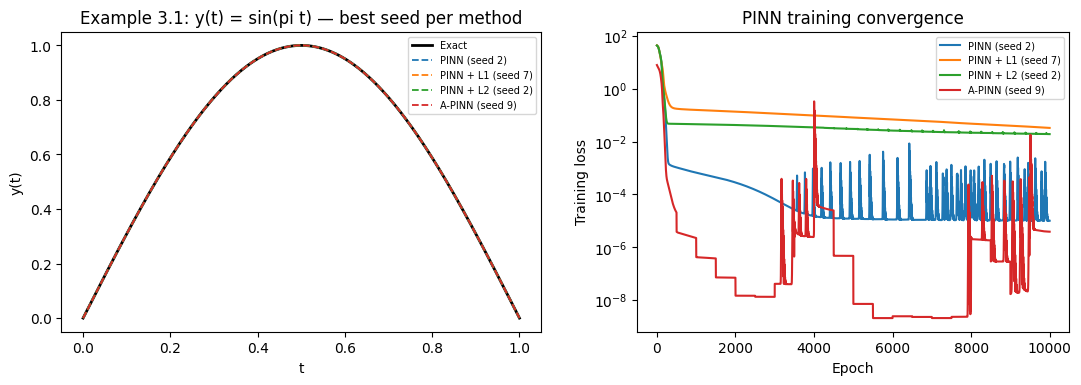

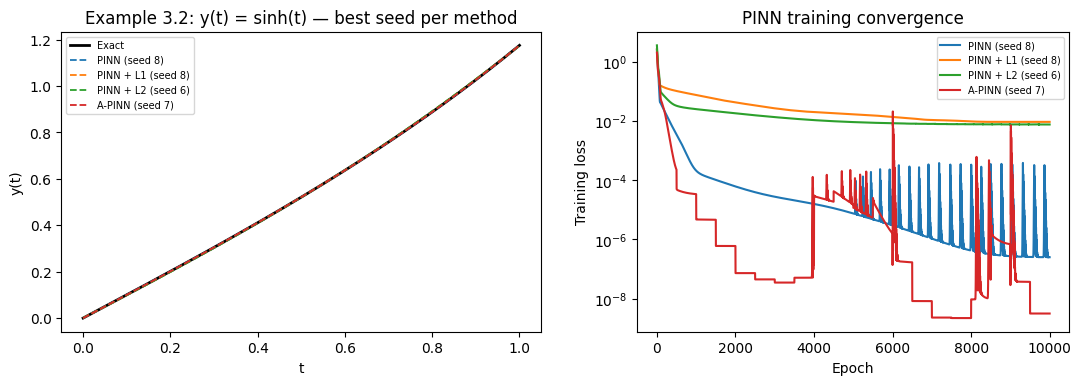

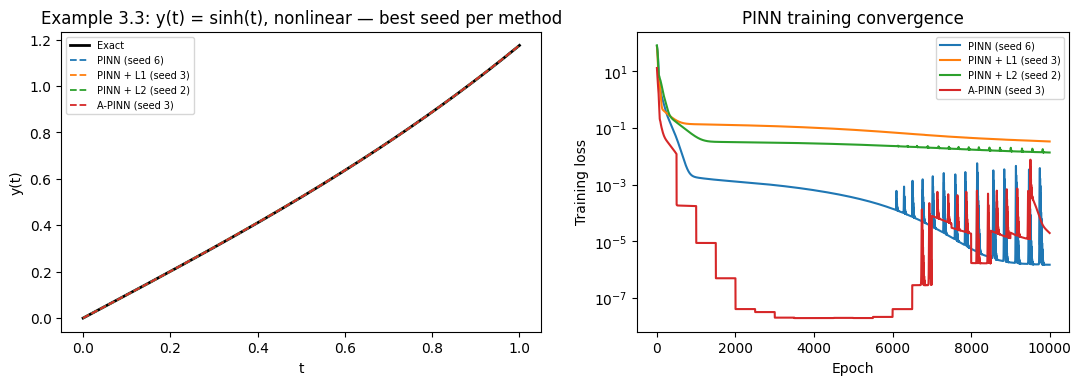

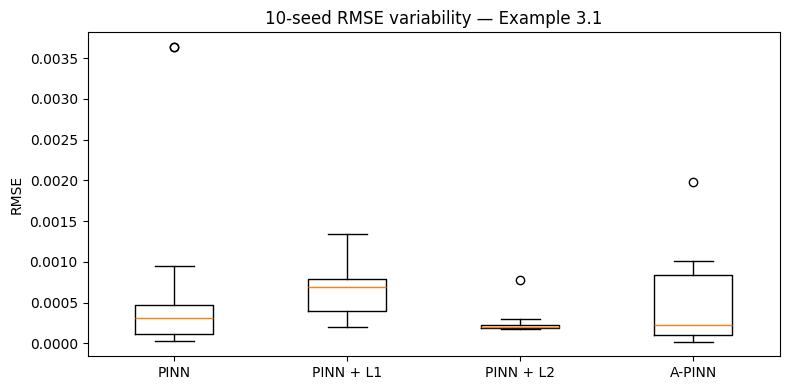

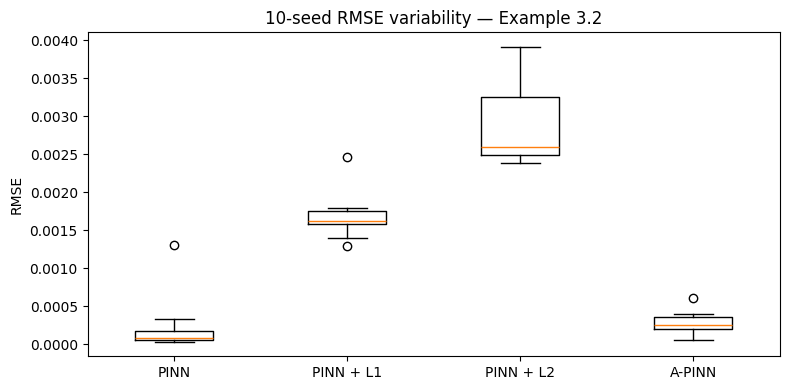

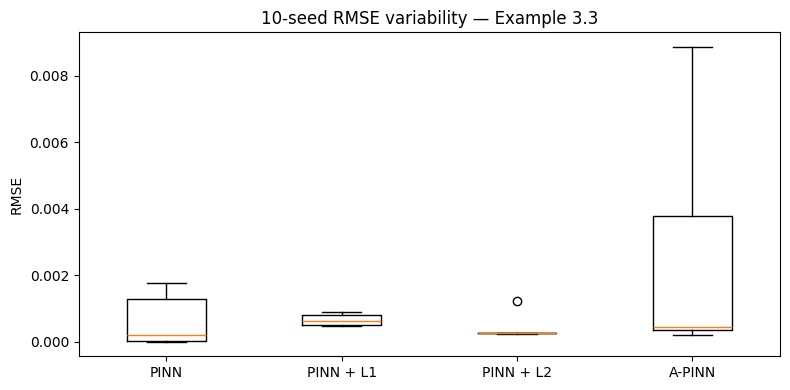

In [13]:
# ============================================================
# 9. MULTI-SEED SOLUTION AND LOSS PLOTS
# ============================================================
# For each method we plot the seed with the lowest RMSE. This avoids
# putting 10 nearly overlapping curves for every method on one figure.

for key, problem in PROBLEMS.items():
    fig = plt.figure(figsize=(12, 4))
    ax1 = fig.add_axes([0.08, 0.15, 0.40, 0.75])
    ax2 = fig.add_axes([0.56, 0.15, 0.36, 0.75])

    # Exact solution from any stored run.
    first_mode = MODES[0]
    first_seed = SEEDS[0]
    ref = prediction_records[(key, first_mode, first_seed)]
    ax1.plot(ref["t"], ref["y_true"], "k-", linewidth=2, label="Exact")

    for mode in MODES:
        group = runs_df[(runs_df["Example"] == key) & (runs_df["Mode"] == mode)]
        best_seed = int(group.loc[group["RMSE"].idxmin(), "Seed"])
        r = prediction_records[(key, mode, best_seed)]
        ax1.plot(r["t"], r["y_pred"], "--", linewidth=1.3,
                 label=f"{MODE_LABELS[mode]} (seed {best_seed})")
        ax2.plot(r["history"], label=f"{MODE_LABELS[mode]} (seed {best_seed})")

    ax1.set_title(problem.name + " — best seed per method")
    ax1.set_xlabel("t")
    ax1.set_ylabel("y(t)")
    ax1.legend(fontsize=7)

    ax2.set_yscale("log")
    ax2.set_xlabel("Epoch")
    ax2.set_ylabel("Training loss")
    ax2.set_title("PINN training convergence")
    ax2.legend(fontsize=7)

    plt.show()

# ------------------------------------------------------------
# Seed variability: RMSE distribution
# ------------------------------------------------------------
for key in PROBLEMS:
    sub = runs_df[runs_df["Example"] == key]
    plt.figure(figsize=(8, 4))
    data = [sub[sub["Mode"] == mode]["RMSE"].values for mode in MODES]
    plt.boxplot(data)
    plt.xticks(range(1, len(MODES) + 1), [MODE_LABELS[m] for m in MODES])
    plt.ylabel("RMSE")
    plt.title(f"10-seed RMSE variability — Example {key}")
    plt.tight_layout()
    plt.show()

## Paper-style figure sweeps (auxiliary, one seed)

The paper's Figures 2–4, 6–8 and 10–12 vary hidden-layer depth and activation function. To reproduce those **types of graphs** without multiplying the main 10-seed experiment by another 100+ runs, this notebook uses a clearly separated auxiliary sweep: **1 seed, 3,000 epochs, 500 collocation points**. The main project results remain the 10-seed × 10,000-epoch experiment. The paper specifically discusses depths 3, 6, 9, 12 and 15 and activation functions tanh, sigmoid, ReLU and SeLU.

In [14]:
# ============================================================
# AUXILIARY PAPER-STYLE SWEEP SETTINGS
# ============================================================
AUX_SEED = 0
AUX_EPOCHS = 20 if QUICK_TEST else 3000
AUX_COLLOC = 300 if QUICK_TEST else 500
DEPTHS = [3, 6] if QUICK_TEST else [3, 6, 9, 12, 15]
ACTIVATIONS = ["tanh", "sigmoid"] if QUICK_TEST else ["tanh", "sigmoid", "relu", "selu"]

print(f"Auxiliary sweeps: seed={AUX_SEED}, epochs={AUX_EPOCHS}, collocation={AUX_COLLOC}")
print("Depths:", DEPTHS)
print("Activations:", ACTIVATIONS)


Auxiliary sweeps: seed=0, epochs=3000, collocation=500
Depths: [3, 6, 9, 12, 15]
Activations: ['tanh', 'sigmoid', 'relu', 'selu']


In [15]:
# ============================================================
# RUN DEPTH + ACTIVATION SWEEPS FOR FIGURES 2–4, 6–8, 10–12
# ============================================================
aux_records = []
aux_checkpoint = os.path.join(OUT_DIR, "pinn_paper_figure_sweep_checkpoint.pkl")
aux_expected = []
for key in PROBLEMS:
    for mode in MODES:
        for depth in DEPTHS:
            aux_expected.append(("depth", key, mode, depth))
        for act in ACTIVATIONS:
            aux_expected.append(("activation", key, mode, act))

if RESUME and os.path.exists(aux_checkpoint):
    try:
        with open(aux_checkpoint, "rb") as f:
            aux_records = pickle.load(f)
        print(f"Resumed auxiliary sweep: {len(aux_records)}/{len(aux_expected)}")
    except Exception:
        aux_records = []

completed_aux = {(r["Sweep"], r["Example"], r["Method"], r["Setting"]) for r in aux_records}

for sweep_type, key, mode, setting in aux_expected:
    run_key = (sweep_type, key, mode, setting)
    if run_key in completed_aux:
        continue

    if sweep_type == "depth":
        depth = int(setting)
        activation = "tanh"
    else:
        depth = DEPTH
        activation = str(setting)

    print(f"Aux | {sweep_type} | {key} | {MODE_LABELS[mode]} | {setting}")
    net, history, elapsed = train(
        PROBLEMS[key], mode=mode, epochs=AUX_EPOCHS,
        n_colloc=AUX_COLLOC, lr=LR, seed=AUX_SEED,
        width=HIDDEN, depth=depth, activation=activation
    )
    _, _, _, stats = evaluate(net, PROBLEMS[key])
    aux_records.append({
        "Sweep": sweep_type, "Example": key, "Method": MODE_LABELS[mode],
        "Mode": mode, "Setting": setting, "Activation": activation,
        "Depth": depth, "Width": HIDDEN, "Seed": AUX_SEED,
        "Epochs": AUX_EPOCHS, "RMSE": stats["RMSE"],
        "RE": stats["RE"], "MAPE (%)": stats["MAPE (%)"],
        "MSE": stats["RMSE"]**2, "Time (s)": elapsed
    })
    with open(aux_checkpoint, "wb") as f:
        pickle.dump(aux_records, f, protocol=pickle.HIGHEST_PROTOCOL)
    del net
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

aux_df = pd.DataFrame(aux_records)
aux_df.to_csv(os.path.join(OUT_DIR, "pinn_paper_figure_sweeps.csv"), index=False)
print(f"Completed {len(aux_df)}/{len(aux_expected)} auxiliary runs")
display(aux_df.round(6))


Aux | depth | 3.1 | PINN | 3
Aux | depth | 3.1 | PINN | 6
Aux | depth | 3.1 | PINN | 9
Aux | depth | 3.1 | PINN | 12
Aux | depth | 3.1 | PINN | 15
Aux | activation | 3.1 | PINN | tanh
Aux | activation | 3.1 | PINN | sigmoid
Aux | activation | 3.1 | PINN | relu
Aux | activation | 3.1 | PINN | selu
Aux | depth | 3.1 | PINN + L1 | 3
Aux | depth | 3.1 | PINN + L1 | 6
Aux | depth | 3.1 | PINN + L1 | 9
Aux | depth | 3.1 | PINN + L1 | 12
Aux | depth | 3.1 | PINN + L1 | 15


c:\Users\gopim\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\gopim\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Aux | activation | 3.1 | PINN + L1 | tanh
Aux | activation | 3.1 | PINN + L1 | sigmoid
Aux | activation | 3.1 | PINN + L1 | relu
Aux | activation | 3.1 | PINN + L1 | selu
Aux | depth | 3.1 | PINN + L2 | 3
Aux | depth | 3.1 | PINN + L2 | 6
Aux | depth | 3.1 | PINN + L2 | 9
Aux | depth | 3.1 | PINN + L2 | 12
Aux | depth | 3.1 | PINN + L2 | 15
Aux | activation | 3.1 | PINN + L2 | tanh
Aux | activation | 3.1 | PINN + L2 | sigmoid
Aux | activation | 3.1 | PINN + L2 | relu
Aux | activation | 3.1 | PINN + L2 | selu
Aux | depth | 3.1 | A-PINN | 3
Aux | depth | 3.1 | A-PINN | 6
Aux | depth | 3.1 | A-PINN | 9
Aux | depth | 3.1 | A-PINN | 12
Aux | depth | 3.1 | A-PINN | 15
Aux | activation | 3.1 | A-PINN | tanh
Aux | activation | 3.1 | A-PINN | sigmoid
Aux | activation | 3.1 | A-PINN | relu
Aux | activation | 3.1 | A-PINN | selu
Aux | depth | 3.2 | PINN | 3
Aux | depth | 3.2 | PINN | 6
Aux | depth | 3.2 | PINN | 9
Aux | depth | 3.2 | PINN | 12
Aux | depth | 3.2 | PINN | 15
Aux | activation | 3.2 

,Sweep,Example,Method,Mode,Setting,Activation,Depth,Width,Seed,Epochs,RMSE,RE,MAPE (%),MSE,Time (s)
0,depth,3.1,PINN,standard,3,tanh,3,20,0,3000,0.000146,0.000207,0.034723,0.000000,8.420437
1,depth,3.1,PINN,standard,6,tanh,6,20,0,3000,0.000761,0.001077,0.418357,0.000001,14.230205
2,depth,3.1,PINN,standard,9,tanh,9,20,0,3000,0.001483,0.002098,0.704910,0.000002,20.196803
3,depth,3.1,PINN,standard,12,tanh,12,20,0,3000,0.000117,0.000165,0.036391,0.000000,26.768918
4,depth,3.1,PINN,standard,15,tanh,15,20,0,3000,0.000177,0.000251,0.060047,0.000000,32.478385
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,depth,3.3,A-PINN,apinn,15,tanh,15,20,0,3000,0.000683,0.001070,0.240923,0.000000,41.213796
104,activation,3.3,A-PINN,apinn,tanh,tanh,3,20,0,3000,0.008426,0.013207,3.034024,0.000071,10.525970
105,activation,3.3,A-PINN,apinn,sigmoid,sigmoid,3,20,0,3000,0.028061,0.043986,10.037333,0.000787,10.308293
106,activation,3.3,A-PINN,apinn,relu,relu,3,20,0,3000,0.039231,0.061493,9.306529,0.001539,8.677620


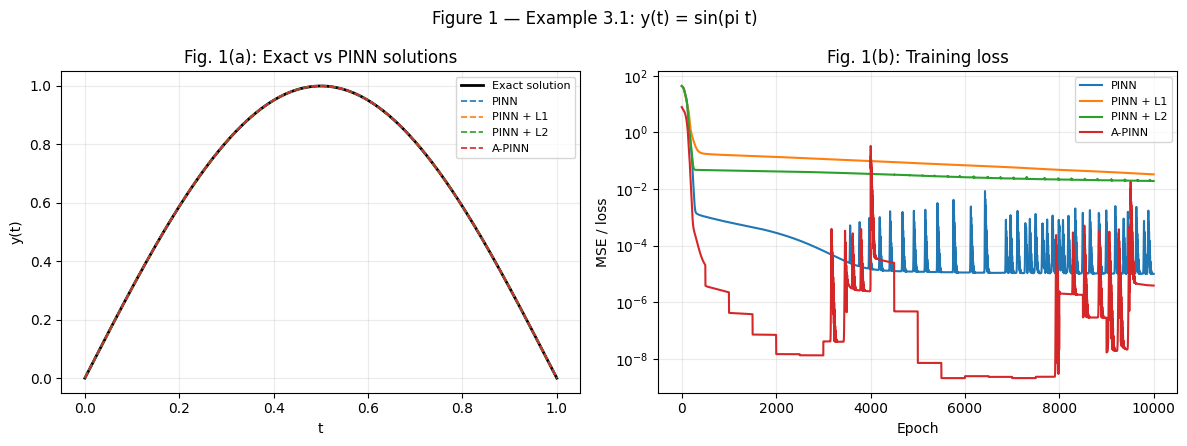

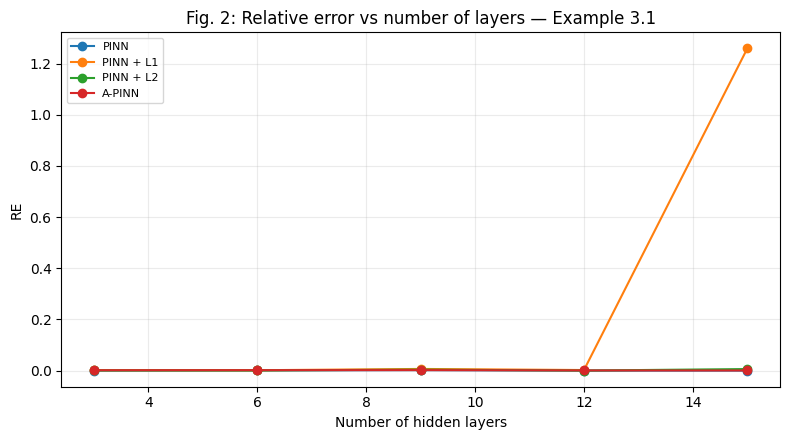

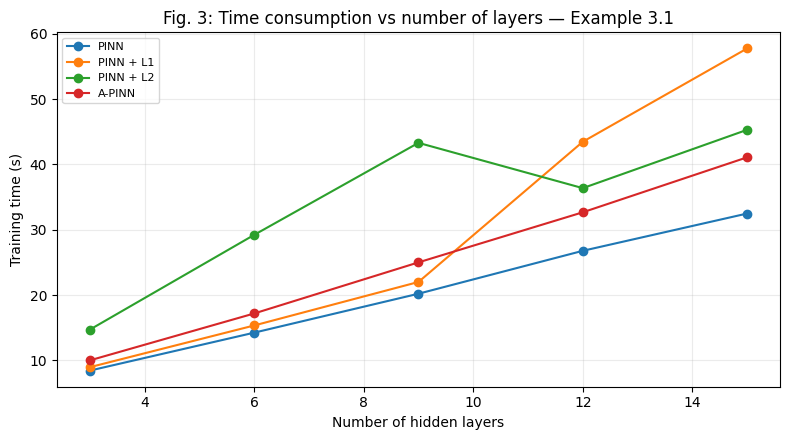

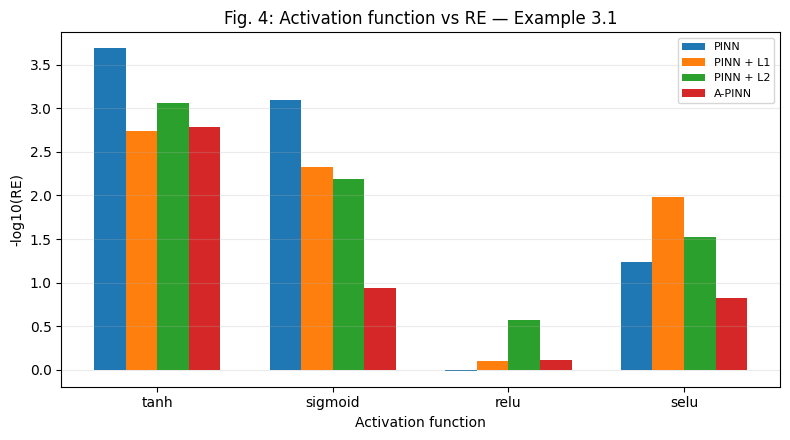

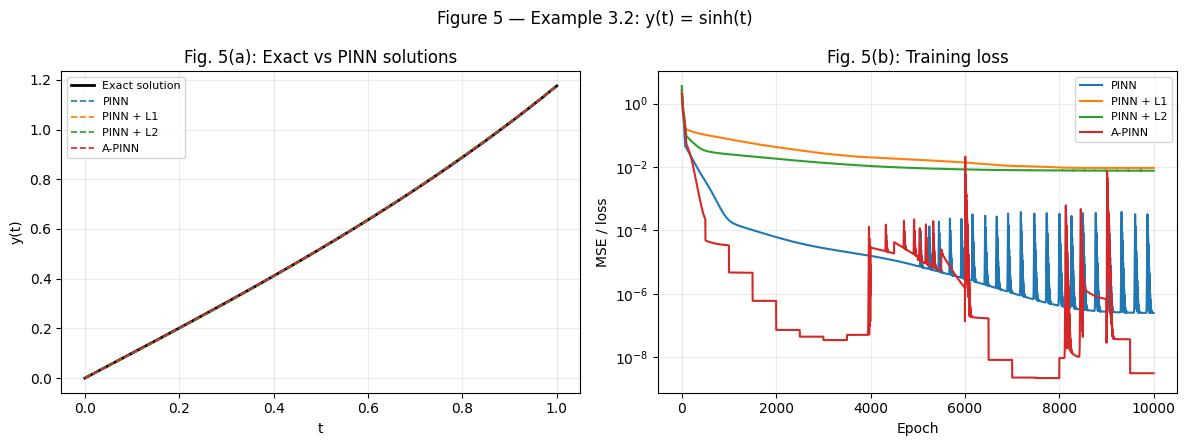

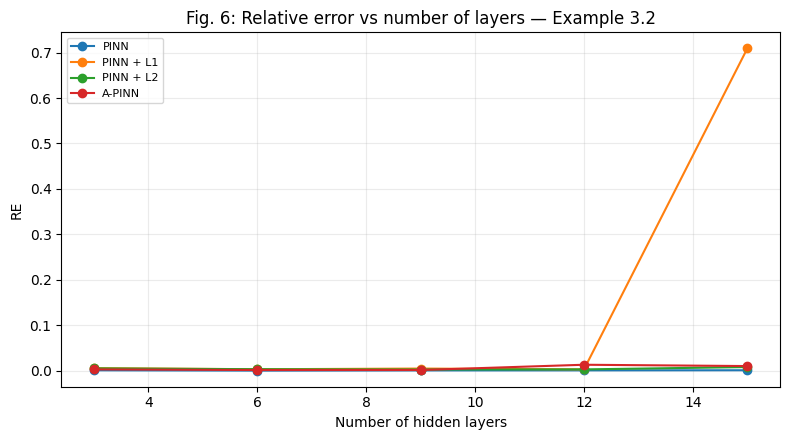

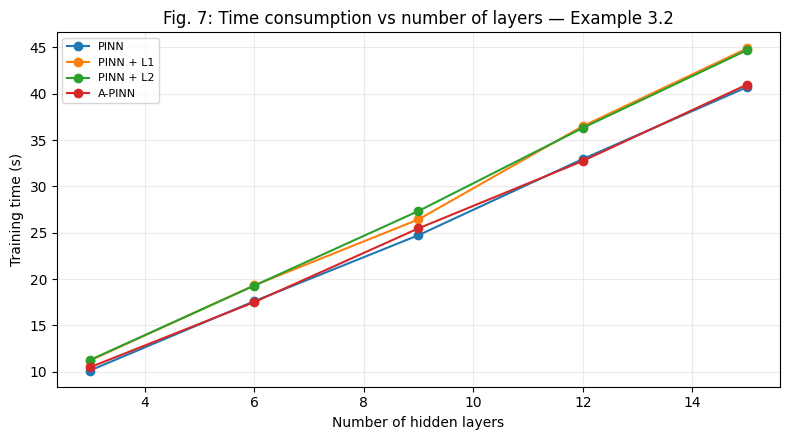

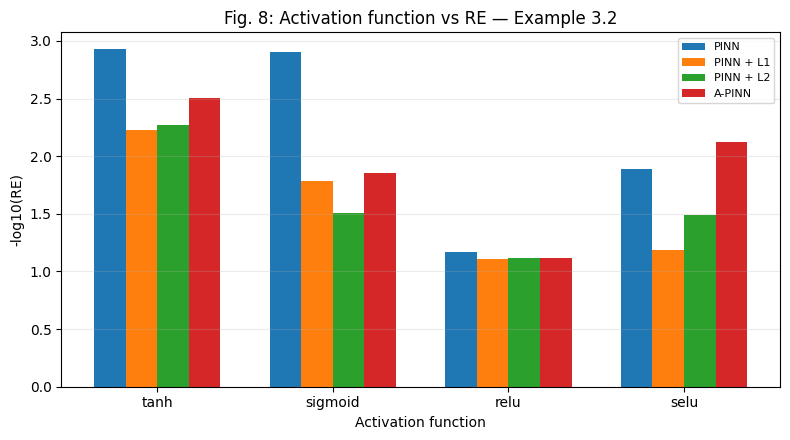

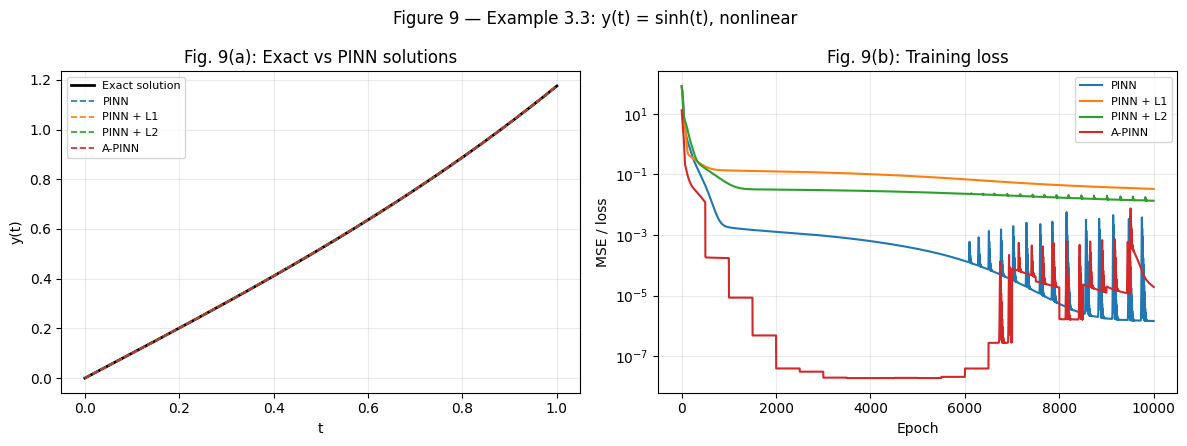

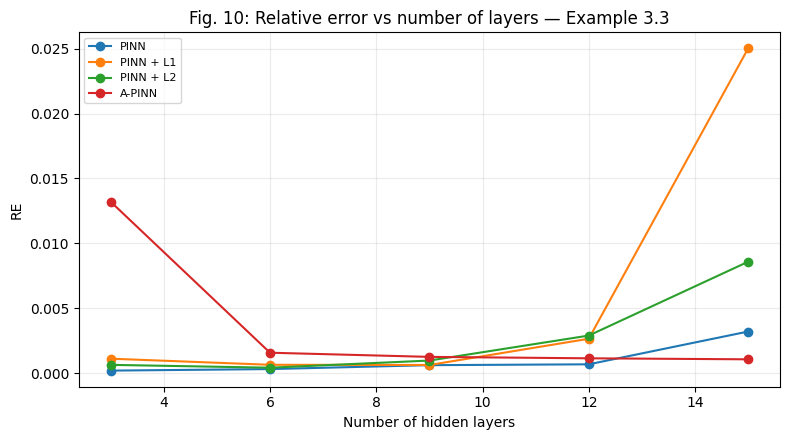

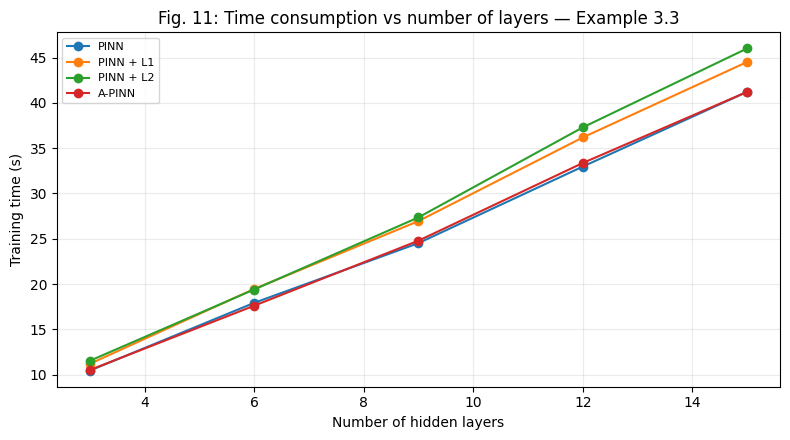

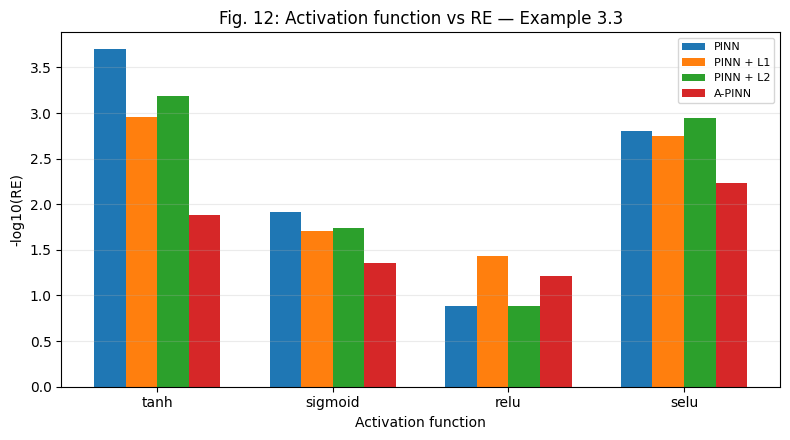

In [16]:
# ============================================================
# FIGURES 1–12 — PAPER-STYLE RECREATIONS FROM OUR RESULTS
# ============================================================
# Figures 1,5,9: solution + MSE.
# Figures 2,6,10: relative error vs depth.
# Figures 3,7,11: training time vs depth.
# Figures 4,8,12: activation function vs -log10(RE).

def plot_solution_and_loss(example_key, fig_no):
    problem = PROBLEMS[example_key]
    # Use the best-by-mean-RMSE seed from the main 10-seed study for the plot.
    sub = summary_df[summary_df["Example"] == example_key]
    best_row = sub.loc[sub["Mean RMSE"].idxmin()]
    best_mode = next(m for m in MODES if MODE_LABELS[m] == best_row["Method"])
    best_seed = int(best_row["Best seed"])
    rec = prediction_records[(example_key, best_mode, best_seed)]

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].plot(rec["t"], rec["y_true"], "k-", lw=2, label="Exact solution")
    for mode in MODES:
        seeds_here = [s for (k,m,s) in prediction_records.keys() if k==example_key and m==mode]
        if not seeds_here: continue
        s = min(seeds_here, key=lambda ss: next(r["RMSE"] for r in run_records if r["Example"]==example_key and r["Mode"]==mode and int(r["Seed"])==ss))
        rr = prediction_records[(example_key, mode, s)]
        ax[0].plot(rr["t"], rr["y_pred"], "--", lw=1.2, label=MODE_LABELS[mode])
    ax[0].set_xlabel("t"); ax[0].set_ylabel("y(t)"); ax[0].set_title(f"Fig. {fig_no}(a): Exact vs PINN solutions")
    ax[0].legend(fontsize=8); ax[0].grid(alpha=.25)

    for mode in MODES:
        seeds_here = [s for (k,m,s) in prediction_records.keys() if k==example_key and m==mode]
        if not seeds_here: continue
        s = min(seeds_here, key=lambda ss: next(r["RMSE"] for r in run_records if r["Example"]==example_key and r["Mode"]==mode and int(r["Seed"])==ss))
        h = prediction_records[(example_key, mode, s)]["history"]
        ax[1].semilogy(np.arange(1, len(h)+1), np.maximum(h,1e-12), label=MODE_LABELS[mode])
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("MSE / loss")
    ax[1].set_title(f"Fig. {fig_no}(b): Training loss")
    ax[1].legend(fontsize=8); ax[1].grid(alpha=.25)
    fig.suptitle(f"Figure {fig_no} — {problem.name}")
    plt.tight_layout(); plt.show()


def plot_depth_figures(example_key, fig_re, fig_time):
    sub = aux_df[aux_df["Example"] == example_key] if 'aux_df' in globals() else pd.DataFrame()
    d = sub[sub["Sweep"] == "depth"]
    fig, ax = plt.subplots(figsize=(8,4.5))
    for mode in MODES:
        q=d[d["Mode"]==mode].sort_values("Depth")
        ax.plot(q["Depth"], q["RE"], "o-", label=MODE_LABELS[mode])
    ax.set_xlabel("Number of hidden layers"); ax.set_ylabel("RE")
    ax.set_title(f"Fig. {fig_re}: Relative error vs number of layers — Example {example_key}")
    ax.legend(fontsize=8); ax.grid(alpha=.25); plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(8,4.5))
    for mode in MODES:
        q=d[d["Mode"]==mode].sort_values("Depth")
        ax.plot(q["Depth"], q["Time (s)"], "o-", label=MODE_LABELS[mode])
    ax.set_xlabel("Number of hidden layers"); ax.set_ylabel("Training time (s)")
    ax.set_title(f"Fig. {fig_time}: Time consumption vs number of layers — Example {example_key}")
    ax.legend(fontsize=8); ax.grid(alpha=.25); plt.tight_layout(); plt.show()


def plot_activation_figure(example_key, fig_no):
    sub = aux_df[(aux_df["Example"] == example_key) & (aux_df["Sweep"] == "activation")]
    fig, ax = plt.subplots(figsize=(8,4.5))
    x=np.arange(len(ACTIVATIONS)); width=.18
    for j,mode in enumerate(MODES):
        q=sub[sub["Mode"]==mode].set_index("Activation").reindex(ACTIVATIONS)
        ax.bar(x+(j-1.5)*width, -np.log10(np.maximum(q["RE"].to_numpy(),1e-12)), width, label=MODE_LABELS[mode])
    ax.set_xticks(x); ax.set_xticklabels(ACTIVATIONS); ax.set_xlabel("Activation function")
    ax.set_ylabel("-log10(RE)"); ax.set_title(f"Fig. {fig_no}: Activation function vs RE — Example {example_key}")
    ax.legend(fontsize=8); ax.grid(axis="y", alpha=.25); plt.tight_layout(); plt.show()

plot_solution_and_loss("3.1", 1)
plot_depth_figures("3.1", 2, 3)
plot_activation_figure("3.1", 4)
plot_solution_and_loss("3.2", 5)
plot_depth_figures("3.2", 6, 7)
plot_activation_figure("3.2", 8)
plot_solution_and_loss("3.3", 9)
plot_depth_figures("3.3", 10, 11)
plot_activation_figure("3.3", 12)


## 11. Finite-difference numerical solver

This is the main numerical baseline for the extension. Instead of learning the solution, the ODE is discretized directly on a grid using central finite differences, while the three-point boundary condition is imposed directly in the nonlinear algebraic system.

The implementation uses an analytic sparse Jacobian and sparse Newton iterations, with backtracking for the nonlinear Example 3.3. The ODE is enforced only at interior grid points, so the singular endpoint coefficients are never evaluated at t=0 or t=1.

In [17]:
def finite_difference_system(key, N=FD_N):
    """Build F(y) and an analytic sparse Jacobian for the stabilized ODE."""
    problem = PROBLEMS[key]

    if abs(problem.theta * N - round(problem.theta * N)) > 1e-12:
        raise ValueError(f"N={N} must make theta={problem.theta} a grid point.")

    h = 1.0 / N
    x = np.linspace(0.0, 1.0, N + 1)
    j = int(round(problem.theta * N))

    def F(y):
        out = np.zeros(N + 1, dtype=float)
        out[0] = y[0] - problem.alpha

        for i in range(1, N):
            ti = x[i]
            yp = (y[i+1] - y[i-1]) / (2.0*h)
            ypp = (y[i+1] - 2.0*y[i] + y[i-1]) / (h*h)

            if key == "3.1":
                out[i] = (ti*ypp + 2.0*yp
                          + math.pi**2 * ti * math.sin(math.pi*ti)
                          - 2.0*math.pi*math.cos(math.pi*ti))
            elif key == "3.2":
                out[i] = (ti*(1.0-ti)*ypp + (1.0-ti)*yp + y[i]
                          - math.sinh(ti) - (1.0-ti)*math.cosh(ti)
                          - ti*(1.0-ti)*math.sinh(ti))
            elif key == "3.3":
                out[i] = (ti*(1.0-ti)*ypp + 6.0*yp + y[i]**2 + 2.0*y[i]
                          - 6.0*math.cosh(ti)
                          - math.sinh(ti)*(math.sinh(ti)-ti**2+ti+2.0))

        out[N] = y[N] - problem.epsilon*y[j] - problem.beta
        return out

    def J(y):
        A = lil_matrix((N + 1, N + 1), dtype=float)
        A[0, 0] = 1.0

        for i in range(1, N):
            ti = x[i]
            a = ti if key == "3.1" else ti*(1.0-ti)
            c = a / (h*h)
            d = 1.0 / (2.0*h)

            if key == "3.1":
                A[i, i-1] = c - 2.0*d
                A[i, i] = -2.0*c
                A[i, i+1] = c + 2.0*d
            elif key == "3.2":
                A[i, i-1] = c - (1.0-ti)*d
                A[i, i] = -2.0*c + 1.0
                A[i, i+1] = c + (1.0-ti)*d
            elif key == "3.3":
                A[i, i-1] = c - 6.0*d
                A[i, i] = -2.0*c + 2.0*y[i] + 2.0
                A[i, i+1] = c + 6.0*d

        A[N, N] = 1.0
        A[N, j] -= problem.epsilon
        return A.tocsr()

    return x, F, J


def solve_finite_difference(key, N=FD_N, tol=1e-10, max_iter=30):
    """Solve the finite-difference system with sparse Newton iterations."""
    x, F, J = finite_difference_system(key, N)
    problem = PROBLEMS[key]

    # Generic boundary-consistent linear initial guess.
    slope = problem.beta / (1.0 - problem.epsilon*problem.theta)
    y = problem.alpha + slope*x

    start = time.perf_counter()
    converged = False
    initial_norm = None

    for it in range(max_iter):
        r = F(y)
        rnorm = np.linalg.norm(r, ord=np.inf)
        if initial_norm is None:
            initial_norm = rnorm
        if rnorm < tol:
            converged = True
            break

        delta = spsolve(J(y), -r)

        # Backtracking makes the nonlinear Example 3.3 robust.
        step = 1.0
        accepted = False
        for _ in range(12):
            y_trial = y + step*delta
            trial_norm = np.linalg.norm(F(y_trial), ord=np.inf)
            if trial_norm < rnorm:
                y = y_trial
                accepted = True
                break
            step *= 0.5

        if not accepted:
            y = y + 0.1*delta

    elapsed = time.perf_counter() - start
    final_norm = float(np.linalg.norm(F(y), ord=np.inf))

    if not converged and final_norm >= tol:
        raise RuntimeError(
            f"Finite-difference Newton failed for {key}: "
            f"final residual {final_norm:.3e} after {max_iter} iterations"
        )

    return x, y, elapsed, final_norm

## 12. Run the numerical solver

In [18]:

fd_results = {}

for key, problem in PROBLEMS.items():

    x_fd, y_fd, elapsed, residual_inf = solve_finite_difference(
        key, N=FD_N
    )

    y_true = problem.exact_fn(x_fd)
    stats = stats_table(y_true, y_fd)

    fd_results[key] = {
        "x": x_fd,
        "y": y_fd,
        "stats": stats,
        "time": elapsed,
        "residual_inf": residual_inf
    }

    print("\n" + problem.name)
    print(
        f"Finite Difference | "
        f"RE={stats['RE']:.10f} | "
        f"RMSE={stats['RMSE']:.10f} | "
        f"MAPE={stats['MAPE (%)']:.6f}% | "
        f"time={elapsed:.3f}s | "
        f"max equation residual={residual_inf:.2e}"
    )



Example 3.1: y(t) = sin(pi t)
Finite Difference | RE=0.0000112592 | RMSE=0.0000079515 | MAPE=0.001802% | time=0.011s | max equation residual=5.13e-11

Example 3.2: y(t) = sinh(t)
Finite Difference | RE=0.0000021331 | RMSE=0.0000013615 | MAPE=0.000924% | time=0.006s | max equation residual=7.13e-12

Example 3.3: y(t) = sinh(t), nonlinear
Finite Difference | RE=0.0000012470 | RMSE=0.0000007959 | MAPE=0.000862% | time=0.018s | max equation residual=5.13e-12


## 13. Direct PINN vs numerical comparison

In [19]:
# ============================================================
# 12. DIRECT MULTI-SEED PINN vs FINITE-DIFFERENCE COMPARISON
# ============================================================
# The main PINN comparison uses the mean RMSE over 10 seeds.
# FD is deterministic, so it has one result for the N=400 grid.

comparison_rows = []

for key, problem in PROBLEMS.items():
    sub = summary_df[summary_df["Example"] == key]
    best_idx = sub["Mean RMSE"].idxmin()
    best = sub.loc[best_idx]
    best_mode = next(m for m in MODES if MODE_LABELS[m] == best["Method"])
    fd = fd_results[key]

    comparison_rows.append({
        "Example": key,
        "Best PINN": best["Method"],
        "PINN mean RMSE": best["Mean RMSE"],
        "PINN RMSE std": best["Std RMSE"],
        "PINN best-seed RMSE": best["Best RMSE"],
        "FD RMSE": fd["stats"]["RMSE"],
        "PINN mean RE": best["Mean RE"],
        "FD RE": fd["stats"]["RE"],
        "PINN mean time (s)": best["Mean Time (s)"],
        "FD time (s)": fd["time"],
        "Mean PINN/FD time": best["Mean Time (s)"] / max(fd["time"], 1e-12),
        "Mean PINN RMSE / FD RMSE": best["Mean RMSE"] / max(fd["stats"]["RMSE"], 1e-15)
    })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(8))

print("\nInterpretation:")
print("• Lower RMSE/RE is better for accuracy.")
print("• Lower wall-clock time is better for computational efficiency.")
print("• The PINN result is summarized across 10 random seeds.")
print("• FD is deterministic for a fixed grid, so no seed averaging is used.")
print("• Timing is hardware/runtime dependent; use it as an empirical measurement, not a universal speed claim.")

,Example,Best PINN,PINN mean RMSE,PINN RMSE std,PINN best-seed RMSE,FD RMSE,PINN mean RE,FD RE,PINN mean time (s),FD time (s),Mean PINN/FD time,Mean PINN RMSE / FD RMSE
0,3.1,PINN + L2,0.000264,0.000185,0.000171,7.950000e-06,0.000373,0.000011,27.580155,0.011312,2438.240279,33.171753
1,3.2,PINN,0.000230,0.000387,0.000033,1.360000e-06,0.000361,0.000002,25.243464,0.005644,4473.015623,169.121561
2,3.3,PINN + L2,0.000357,0.000308,0.000242,8.000000e-07,0.000560,0.000001,34.212736,0.018210,1878.757411,448.749435



Interpretation:
• Lower RMSE/RE is better for accuracy.
• Lower wall-clock time is better for computational efficiency.
• The PINN result is summarized across 10 random seeds.
• FD is deterministic for a fixed grid, so no seed averaging is used.
• Timing is hardware/runtime dependent; use it as an empirical measurement, not a universal speed claim.


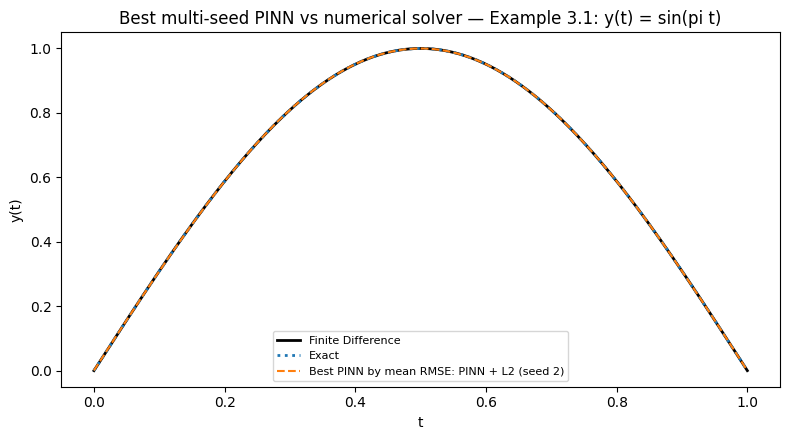

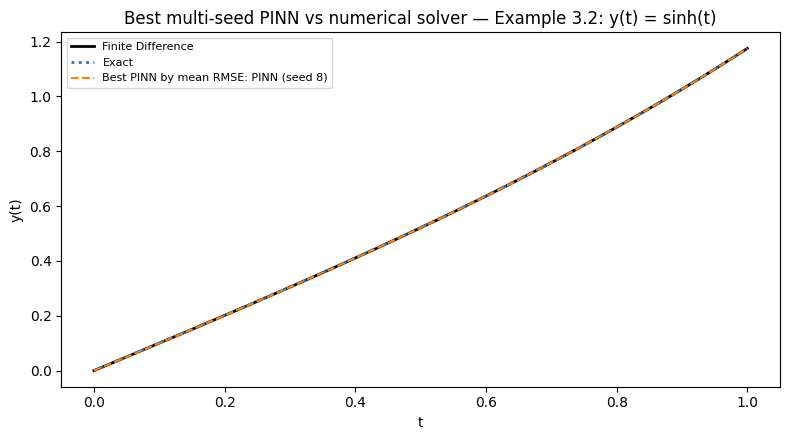

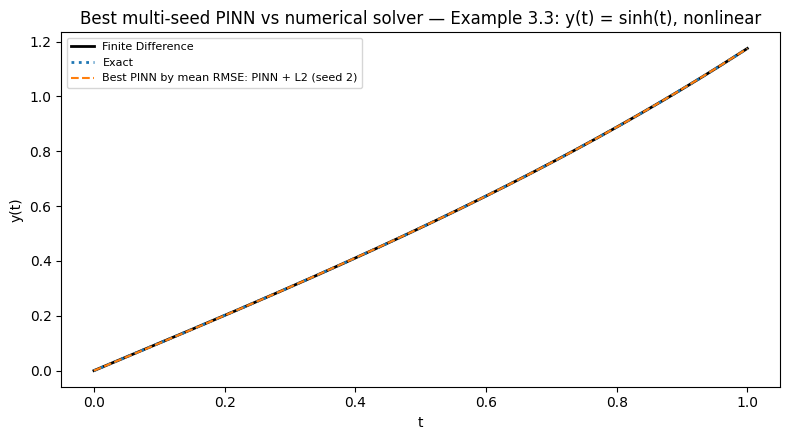

In [20]:
# ============================================================
# 12B. DIRECT SOLUTION PLOTS — BEST PINN SEED VS FD
# ============================================================

for key, problem in PROBLEMS.items():
    sub = summary_df[summary_df["Example"] == key]
    best_row = sub.loc[sub["Mean RMSE"].idxmin()]
    best_mode = next(m for m in MODES if MODE_LABELS[m] == best_row["Method"])
    best_seed = int(best_row["Best seed"])

    plt.figure(figsize=(8, 4.5))

    plt.plot(
        fd_results[key]["x"], fd_results[key]["y"],
        "k-", linewidth=2, label="Finite Difference"
    )

    plt.plot(
        prediction_records[(key, best_mode, best_seed)]["t"],
        prediction_records[(key, best_mode, best_seed)]["y_true"],
        ":", linewidth=2, label="Exact"
    )

    plt.plot(
        prediction_records[(key, best_mode, best_seed)]["t"],
        prediction_records[(key, best_mode, best_seed)]["y_pred"],
        "--", linewidth=1.5,
        label=f"Best PINN by mean RMSE: {MODE_LABELS[best_mode]} (seed {best_seed})"
    )

    plt.title(f"Best multi-seed PINN vs numerical solver — {problem.name}")
    plt.xlabel("t")
    plt.ylabel("y(t)")
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


# 13. Finite-difference convergence study

A numerical method should not be judged from a single grid size.

We therefore repeat the finite-difference calculation for

\[
N=50,\;100,\;200,\;400.
\]

If the error decreases as the grid is refined, that gives evidence that the
numerical result is converging rather than being an accidental good fit.


,Example,N,RMSE,RE,Time (s),Max residual
0,3.1,50,5.054401e-04,0.000722,0.001606,0.000000e+00
1,3.1,100,1.268473e-04,0.000180,0.001624,0.000000e+00
2,3.1,200,3.177440e-05,0.000045,0.003040,0.000000e+00
3,3.1,400,7.951500e-06,0.000011,0.005399,1.000000e-10
4,3.2,50,6.406650e-05,0.000100,0.000790,0.000000e+00
5,3.2,100,1.805760e-05,0.000028,0.001245,0.000000e+00
6,3.2,200,4.994100e-06,0.000008,0.002870,0.000000e+00
7,3.2,400,1.361500e-06,0.000002,0.005785,0.000000e+00
8,3.3,50,5.185440e-05,0.000081,0.002117,0.000000e+00
9,3.3,100,1.283440e-05,0.000020,0.003203,0.000000e+00


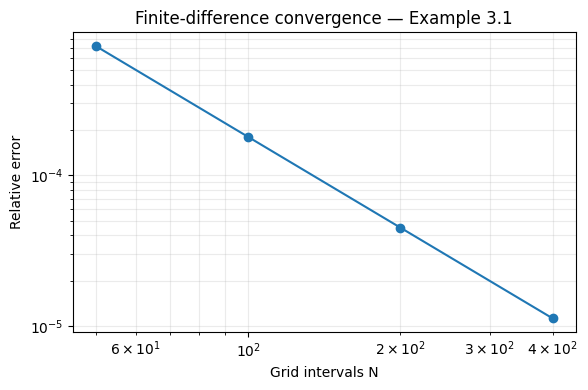

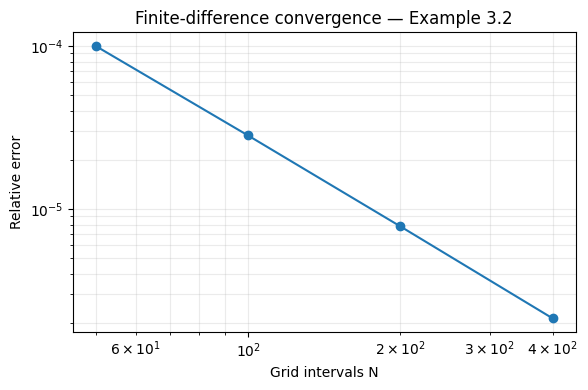

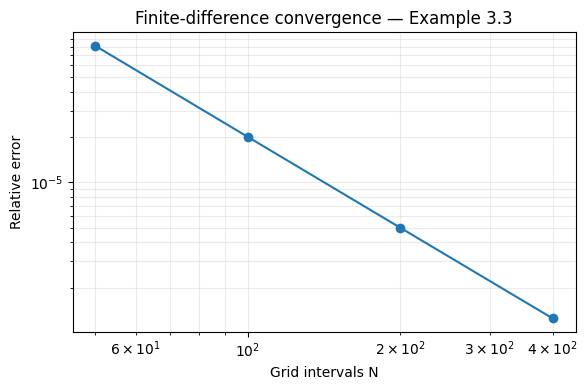

Saved: outputs/fd_convergence_results.csv


In [21]:
# ============================================================
# 13. FINITE-DIFFERENCE GRID-CONVERGENCE STUDY
# ============================================================

fd_convergence = []

for key, problem in PROBLEMS.items():
    for N in FD_GRID_SIZES:
        x_fd, y_fd, elapsed, residual_inf = solve_finite_difference(key, N=N)
        y_true = problem.exact_fn(x_fd)
        stats = stats_table(y_true, y_fd)

        fd_convergence.append({
            "Example": key,
            "N": N,
            "RMSE": stats["RMSE"],
            "RE": stats["RE"],
            "Time (s)": elapsed,
            "Max residual": residual_inf
        })

fd_conv_df = pd.DataFrame(fd_convergence)
display(fd_conv_df.round(10))

for key in PROBLEMS:
    sub = fd_conv_df[fd_conv_df["Example"] == key]
    plt.figure(figsize=(6, 4))
    plt.loglog(sub["N"], sub["RE"], "o-")
    plt.xlabel("Grid intervals N")
    plt.ylabel("Relative error")
    plt.title(f"Finite-difference convergence — Example {key}")
    plt.grid(True, which="both", alpha=0.25)
    plt.tight_layout()
    plt.show()

fd_conv_df.to_csv(os.path.join(OUT_DIR, "fd_convergence_results.csv"), index=False)
print(f"Saved: {OUT_DIR}/fd_convergence_results.csv")

# 15. Paper-figure sweep note

The original implementation also contained large auxiliary experiments such as network-depth sweeps, activation-function sweeps, and the large statistical grid. They are **not executed in this final extension notebook** because they are outside the research question and would unnecessarily increase runtime.

If needed later, they can be restored as a separate notebook rather than mixed into the controlled PINN-vs-numerical experiment.

# 16. What this final notebook contains

### Main project experiment
- Examples 3.1, 3.2 and 3.3
- Standard PINN, PINN+L1, PINN+L2 and A-PINN
- **10 seeds × 10,000 epochs**
- 500 collocation points
- Mean ± standard deviation tables

### Paper-style figure suite
- Figures 1–12 recreated from our own computed results
- Depth sweep: 3, 6, 9, 12, 15 hidden layers
- Activation sweep: tanh, sigmoid, ReLU, SeLU
- Auxiliary sweep uses 1 seed × 3,000 epochs to keep the total runtime practical

### Numerical extension
- Finite-difference solver for the same three benchmarks
- N=400 direct comparison
- N=50, 100, 200, 400 grid convergence

### Paper references
- Tables 1–5 are displayed as separate paper-reference tables
- Our computed Tables 2–4 are kept separate from the paper-reported values

### Scope note
This is a controlled reproduction/extension, not a claim of bit-for-bit reproduction of every paper hyperparameter run. The 10-seed study and finite-difference baseline are project extensions.

## 17. Final interpretation

The next code cell prints the final numerical conclusions from the completed 10-seed experiment.

**Do not interpret finite difference as universally superior to PINNs.** These are smooth, one-dimensional benchmark problems where classical discretization is naturally strong.

In [22]:
# ============================================================
# 16. FINAL AUTOMATED INTERPRETATION
# ============================================================

print("=" * 78)
print("FINAL MULTI-SEED STUDY SUMMARY")
print("=" * 78)
print(f"PINN budget: {len(SEEDS)} seeds × {EPOCHS:,} epochs × {len(MODES)} methods × {len(PROBLEMS)} examples")
print("Finite difference: N=400 main comparison + grid convergence")

for key in PROBLEMS:
    sub = summary_df[summary_df["Example"] == key]
    best_row = sub.loc[sub["Mean RMSE"].idxmin()]
    fd = fd_results[key]

    accuracy_winner = "Finite Difference" if fd["stats"]["RMSE"] < best_row["Mean RMSE"] else "Best PINN"
    speed_winner = "Finite Difference" if fd["time"] < best_row["Mean Time (s)"] else "Best PINN"

    print(f"\n{key}")
    print(f"  Best PINN by mean RMSE : {best_row['Method']}")
    print(f"  Mean PINN RMSE         : {best_row['Mean RMSE']:.6e} ± {best_row['Std RMSE']:.2e}")
    print(f"  Best-seed RMSE         : {best_row['Best RMSE']:.6e} (seed {int(best_row['Best seed'])})")
    print(f"  FD RMSE                : {fd['stats']['RMSE']:.6e}")
    print(f"  Accuracy winner        : {accuracy_winner}")
    print(f"  Mean PINN time         : {best_row['Mean Time (s)']:.4f} s")
    print(f"  FD time                : {fd['time']:.4f} s")
    print(f"  Speed winner           : {speed_winner}")

print("\nRecommended interpretation:")
print("For these three low-dimensional benchmark TPS-BVPs, report the 10-seed")
print("mean ± standard deviation for the PINNs and compare them with the")
print("deterministic finite-difference baseline. The FD grid-convergence")
print("study provides additional evidence that the numerical baseline is converged.")
print("Do not generalize these benchmark results to all differential equations or all PINNs.")

print(f"\nFiles created in ./{OUT_DIR}/:")
print("  pinn_10seed_run_results.csv")
print("  pinn_10seed_summary_results.csv")
print("  fd_convergence_results.csv")
print("  pinn_multiseed_10k_checkpoint.pkl")

FINAL MULTI-SEED STUDY SUMMARY
PINN budget: 10 seeds × 10,000 epochs × 4 methods × 3 examples
Finite difference: N=400 main comparison + grid convergence

3.1
  Best PINN by mean RMSE : PINN + L2
  Mean PINN RMSE         : 2.637658e-04 ± 1.85e-04
  Best-seed RMSE         : 1.708784e-04 (seed 2)
  FD RMSE                : 7.951517e-06
  Accuracy winner        : Finite Difference
  Mean PINN time         : 27.5802 s
  FD time                : 0.0113 s
  Speed winner           : Finite Difference

3.2
  Best PINN by mean RMSE : PINN
  Mean PINN RMSE         : 2.302660e-04 ± 3.87e-04
  Best-seed RMSE         : 3.344811e-05 (seed 8)
  FD RMSE                : 1.361541e-06
  Accuracy winner        : Finite Difference
  Mean PINN time         : 25.2435 s
  FD time                : 0.0056 s
  Speed winner           : Finite Difference

3.3
  Best PINN by mean RMSE : PINN + L2
  Mean PINN RMSE         : 3.571810e-04 ± 3.08e-04
  Best-seed RMSE         : 2.415814e-04 (seed 2)
  FD RMSE          